В данном ноутбуке была реализована и адаптирована под задачу классификации КТ классическая архитектура LeNet-5.

Дополнительно исследовалось влияние размерности входного изображения на результаты классификации.

Был использован датасет с Kaggle: https://www.kaggle.com/datasets/ozguraslank/brain-stroke-ct-dataset

In [ ]:
import os
import glob
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

import tensorflow as tf
from tensorflow.keras import layers, models, callbacks, optimizers
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight


In [ ]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
data_path = "/kaggle/input/brain-stroke-ct/Brain_Stroke_CT_Dataset"
test_path = os.path.join(data_path, "External_Test")

AUTOTUNE = tf.data.AUTOTUNE

class_map = {"Bleeding": 1, "Ischemia": 2, "Normal": 0}
class_names = ["Normal", "Bleeding", "Ischemia"]
num_class = len(class_names)

In [ ]:
img_size = (224, 224)
batch_size = 16

In [ ]:
img_size = (128, 128)
batch_size = 64

In [ ]:
img_size = (64, 64)
batch_size = 32

In [ ]:
img_size = (32, 32)
batch_size = 128

In [ ]:
def safe_decode_png(path):
    img_bytes = tf.io.read_file(path)
    try:
        img = tf.image.decode_png(img_bytes, channels=1) # 1 канал
    except Exception:
        img = tf.image.decode_image(img_bytes, channels=1, expand_animations=False)
    img.set_shape([None, None, 1])
    return img

In [ ]:
def collect_image_pairs(root_dir, class_map):
    pairs = []
    for cls_name, cls_id in class_map.items():
        img_dir = os.path.join(root_dir, cls_name, "PNG")
        if not os.path.exists(img_dir):
            img_dir = os.path.join(root_dir, cls_name, "images")
        if not os.path.exists(img_dir):
            print(f"Нет папки PNG для класса '{cls_name}': tried {img_dir}")
            continue
        imgs = sorted(glob.glob(os.path.join(img_dir, "*.png")))
        for p in imgs:
            pairs.append((p, cls_id))
    return pairs

pairs = collect_image_pairs(data_path, class_map)
print("Всего изображений:", len(pairs))

Всего изображений: 6650


In [ ]:
def balance_by_undersample(pairs, seed=SEED):
    by_class = {}
    for p, c in pairs:
        by_class.setdefault(c, []).append(p)
    sizes = {c: len(lst) for c, lst in by_class.items()}
    print("До undersampling:", sizes)
    min_sz = min(sizes.values())
    rng = random.Random(seed)
    balanced = []
    for c, paths in by_class.items():
        if len(paths) > min_sz:
            sampled = rng.sample(paths, min_sz)
        else:
            sampled = paths.copy()
        balanced += [(p, c) for p in sampled]
    rng.shuffle(balanced)
    sizes_after = {c: sum(1 for _p, cc in balanced if cc == c) for c in by_class}
    print("После undersampling:", sizes_after)
    return balanced

balanced_pairs = balance_by_undersample(pairs)
image_paths = [p for p, c in balanced_pairs]
labels_arr = np.array([c for p, c in balanced_pairs], dtype=np.int32)

До undersampling: {1: 1093, 2: 1130, 0: 4427}
После undersampling: {1: 1093, 2: 1093, 0: 1093}


In [ ]:
train_paths, val_paths, train_labels, val_labels = train_test_split(
    image_paths, labels_arr, test_size=0.30, random_state=SEED, stratify=labels_arr)
print("Train / Val размеры:", len(train_paths), len(val_paths))

Train / Val размеры: 2295 984


In [ ]:
test_csv = os.path.join(test_path, "labels_new.csv")
df_raw = pd.read_csv(test_csv)

df_test = df_raw["labels"].str.split(";", expand=True)
df_test.columns = ["image_id", "Stroke"]
df_test = df_test[df_test["image_id"] != "image_id"]
df_test["image_id"] = df_test["image_id"].astype(str)
df_test["Stroke"] = df_test["Stroke"].astype(int)

test_png_dir = os.path.join(test_path, "PNG")
test_paths = []
test_labels = []
for _, row in df_test.iterrows():
    fname = f"{row['image_id']}.png"
    p = os.path.join(test_png_dir, fname)
    if os.path.exists(p):
        test_paths.append(p)
        test_labels.append(int(row["Stroke"]))
    else:
        pass

test_labels = np.array(test_labels, dtype=np.int32)
print("Test samples:", len(test_paths), "class counts:", {i:int(list(test_labels).count(i)) for i in sorted(set(test_labels))})


Test samples: 200 class counts: {0: 137, 1: 35, 2: 28}


In [ ]:
def preprocess_train_img(img):
    img = tf.image.convert_image_dtype(img, tf.float32)

    if tf.random.uniform([]) < 0.25:
        img = tf.image.adjust_brightness(img, 0.02)

    if tf.random.uniform([]) < 0.20:
        noise = tf.random.normal(tf.shape(img), mean=0.0, stddev=0.01)
        img = tf.clip_by_value(img + noise, 0.0, 1.0)

    img = tf.image.resize(img, img_size)
    img = img * 2.0 - 1.0
    img.set_shape([img_size[0], img_size[1], 1])

    return img


In [ ]:
def preprocess_eval_img(img):
    img = tf.image.convert_image_dtype(img, tf.float32)
    img = tf.image.resize(img, img_size)
    img = img * 2.0 - 1.0
    img.set_shape([img_size[0], img_size[1], 1])
    return img


In [ ]:
def parse_train(path, label):
    img = safe_decode_png(path)
    img = preprocess_train_img(img)
    return img, label


In [ ]:
def parse_eval(path, label):
    img = safe_decode_png(path)
    img = preprocess_eval_img(img)
    return img, label


In [ ]:
def build_dataset(paths, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(buffer_size=len(paths), seed=SEED)
        ds = ds.map(parse_train, num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(parse_eval, num_parallel_calls=AUTOTUNE)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = build_dataset(train_paths, train_labels, training=True)
val_ds = build_dataset(val_paths, val_labels, training=False)
test_ds = build_dataset(test_paths, test_labels, training=False)


In [ ]:
for imgs, labs in train_ds.take(1):
    print("Train batch:", imgs.shape, imgs.dtype, "labels:", labs.numpy()[:8])
for imgs, labs in val_ds.take(1):
    print("Val batch:", imgs.shape)
for imgs, labs in test_ds.take(1):
    print("Test batch:", imgs.shape)

Train batch: (32, 64, 64, 1) <dtype: 'float32'> labels: [2 0 1 0 2 2 2 1]
Val batch: (32, 64, 64, 1)
Test batch: (32, 64, 64, 1)


In [ ]:
cls_ids = np.unique(train_labels)
cw_arr = compute_class_weight(class_weight='balanced', classes=cls_ids, y=train_labels)

class_weights = {int(c): float(w) for c, w in zip(cls_ids, cw_arr)}
print("Class weights:", class_weights)

Class weights: {0: 1.0, 1: 1.0, 2: 1.0}


ОРИГИНАЛЬНАЯ АРХИТЕКТУРА С РАЗМЕРОМ ВХОДА 32

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

def build_lenet5(input_shape=(32, 32, 1), num_classes=3):
    inputs = layers.Input(shape=input_shape, name="input")

    x = layers.Conv2D(filters=6, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C1_conv")(inputs)

    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S2_pool")(x)

    x = layers.Conv2D(filters=16, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C3_conv")(x)

    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S4_pool")(x)

    x = layers.Conv2D(filters=120, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C5_conv")(x)

    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(84, activation=tf.nn.tanh, name="F6_dense")(x)

    outputs = layers.Dense(num_classes, activation='softmax', name="output")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="LeNet-5_classical")
    return model

model = build_lenet5()
model.summary()

Model: "LeNet-5_classical"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1_conv (Conv2D)                │ (None, 28, 28, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_pool (AveragePooling2D)      │ (None, 14, 14, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_conv (Conv2D)                │ (None, 10, 10, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_pool (AveragePooling2D)      │ (None, 5, 5, 16)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_conv (Conv2D)                │ (None, 1, 1, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 120)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_dense (Dense)                │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 61,111 (238.71 KB)

 Trainable params: 61,111 (238.71 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

ckpt_path = "best_lenet_model.h5"
ckpt = ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
es = EarlyStopping(monitor="val_loss", mode="min", patience=8, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)

In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=150, class_weight=class_weights, callbacks=[ckpt, es, rlr], verbose=1)

Epoch 1/150


I0000 00:00:1764946598.595852     110 service.cc:148] XLA service 0x7d46b40179d0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1764946598.596667     110 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1764946598.596687     110 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1764946598.807674     110 cuda_dnn.cc:529] Loaded cuDNN version 90300


 1/18 ━━━━━━━━━━━━━━━━━━━━ 1:08 4s/step - accuracy: 0.3047 - loss: 1.1152

I0000 00:00:1764946601.495770     110 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 278ms/step - accuracy: 0.3856 - loss: 1.0889
Epoch 1: val_accuracy improved from -inf to 0.45427, saving model to best_lenet_model.h5


18/18 ━━━━━━━━━━━━━━━━━━━━ 12s 456ms/step - accuracy: 0.3874 - loss: 1.0876 - val_accuracy: 0.4543 - val_loss: 1.0345 - learning_rate: 0.0100
Epoch 2/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 247ms/step - accuracy: 0.4932 - loss: 1.0048
Epoch 2: val_accuracy improved from 0.45427 to 0.47053, saving model to best_lenet_model.h5


... (25 outputs left out)

18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step - accuracy: 0.7019 - loss: 0.6843 - val_accuracy: 0.6352 - val_loss: 0.8505 - learning_rate: 0.0012
Epoch 56/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step - accuracy: 0.7093 - loss: 0.6944
Epoch 56: val_accuracy did not improve from 0.63516
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 319ms/step - accuracy: 0.7088 - loss: 0.6945 - val_accuracy: 0.6270 - val_loss: 0.8477 - learning_rate: 0.0012
Epoch 57/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 231ms/step - accuracy: 0.6951 - loss: 0.6856
Epoch 57: val_accuracy did not improve from 0.63516
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 382ms/step - accuracy: 0.6950 - loss: 0.6861 - val_accuracy: 0.6220 - val_loss: 0.8532 - learning_rate: 0.0012
Epoch 58/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 238ms/step - accuracy: 0.6912 - loss: 0.7092
Epoch 58: val_accuracy did not improve from 0.63516
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 328ms/step - accuracy: 0.6915 - loss: 0.7086 - val_accuracy: 0.6250 - val_loss: 0.8546 - learning_rate: 0.0012
Epoch 59/150
18/

18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 318ms/step - accuracy: 0.6957 - loss: 0.6921 - val_accuracy: 0.6413 - val_loss: 0.8460 - learning_rate: 0.0012
Epoch 67/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 235ms/step - accuracy: 0.7100 - loss: 0.6713
Epoch 67: val_accuracy did not improve from 0.64126
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 324ms/step - accuracy: 0.7097 - loss: 0.6716 - val_accuracy: 0.6250 - val_loss: 0.8441 - learning_rate: 0.0012
Epoch 68/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 228ms/step - accuracy: 0.7077 - loss: 0.6622
Epoch 68: val_accuracy did not improve from 0.64126

Epoch 68: ReduceLROnPlateau reducing learning rate to 0.0006249999860301614.
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 317ms/step - accuracy: 0.7071 - loss: 0.6632 - val_accuracy: 0.6240 - val_loss: 0.8471 - learning_rate: 0.0012
Epoch 69/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.7296 - loss: 0.6591
Epoch 69: val_accuracy did not improve from 0.64126
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 318ms/step - accuracy: 0.7289 - loss: 0.6599 - va

18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 331ms/step - accuracy: 0.7369 - loss: 0.6467 - val_accuracy: 0.6443 - val_loss: 0.8283 - learning_rate: 3.1250e-04
Epoch 93/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 268ms/step - accuracy: 0.7304 - loss: 0.6521
Epoch 93: val_accuracy did not improve from 0.64431
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 362ms/step - accuracy: 0.7302 - loss: 0.6520 - val_accuracy: 0.6352 - val_loss: 0.8269 - learning_rate: 3.1250e-04
Epoch 94/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 241ms/step - accuracy: 0.7337 - loss: 0.6406
Epoch 94: val_accuracy did not improve from 0.64431
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 335ms/step - accuracy: 0.7336 - loss: 0.6411 - val_accuracy: 0.6352 - val_loss: 0.8287 - learning_rate: 3.1250e-04
Epoch 95/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.7342 - loss: 0.6359
Epoch 95: val_accuracy did not improve from 0.64431
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 318ms/step - accuracy: 0.7337 - loss: 0.6364 - val_accuracy: 0.6321 - val_loss: 0.8270 - learning_rate: 3.1250e-04



Epoch 96: ReduceLROnPlateau reducing learning rate to 0.00015624999650754035.
18/18 ━━━━━━━━━━━━━━━━━━━━ 10s 321ms/step - accuracy: 0.7238 - loss: 0.6493 - val_accuracy: 0.6474 - val_loss: 0.8293 - learning_rate: 3.1250e-04
Epoch 97/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 244ms/step - accuracy: 0.7155 - loss: 0.6741
Epoch 97: val_accuracy did not improve from 0.64736
18/18 ━━━━━━━━━━━━━━━━━━━━ 7s 396ms/step - accuracy: 0.7161 - loss: 0.6727 - val_accuracy: 0.6392 - val_loss: 0.8265 - learning_rate: 1.5625e-04
Epoch 98/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step - accuracy: 0.7286 - loss: 0.6460
Epoch 98: val_accuracy did not improve from 0.64736
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 316ms/step - accuracy: 0.7285 - loss: 0.6460 - val_accuracy: 0.6423 - val_loss: 0.8267 - learning_rate: 1.5625e-04
Epoch 99/150
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 230ms/step - accuracy: 0.7331 - loss: 0.6410
Epoch 99: val_accuracy did not improve from 0.64736
18/18 ━━━━━━━━━━━━━━━━━━━━ 6s 319ms/step - accuracy: 0.7331 - los

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 685ms/step - accuracy: 0.5493 - loss: 0.9683

Test Loss: 0.9510
Test Accuracy: 0.5700


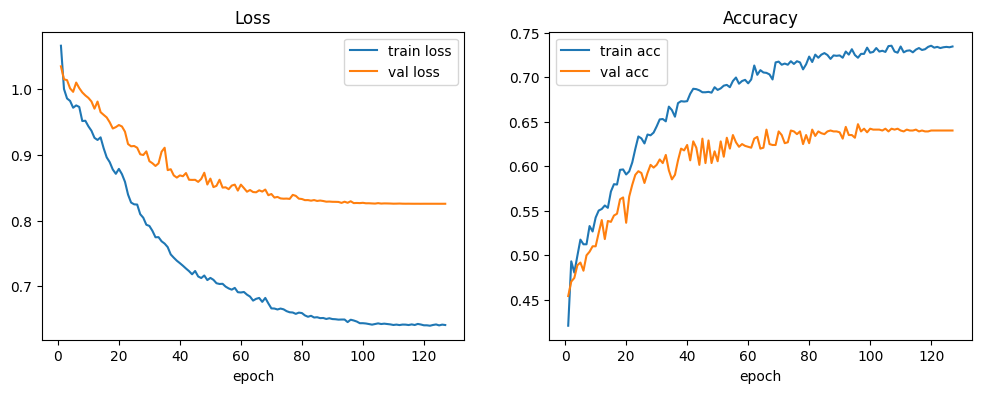

In [ ]:
def plot_history(history):
    h = history.history
    epochs = range(1, len(h['loss'])+1)

    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, h['loss'], label='train loss')
    plt.plot(epochs, h['val_loss'], label='val loss')
    plt.xlabel('epoch'); plt.legend(); plt.title('Loss')

    plt.subplot(1,2,2)
    plt.plot(epochs, h['accuracy'], label='train acc')
    plt.plot(epochs, h.get('val_accuracy', []), label='val acc')
    plt.xlabel('epoch'); plt.legend(); plt.title('Accuracy')

    plt.show()

plot_history(history)


Classification Report:
              precision    recall  f1-score   support

      Normal     0.8488    0.5328    0.6547       137
    Bleeding     0.4138    0.6857    0.5161        35
    Ischemia     0.3036    0.6071    0.4048        28

    accuracy                         0.5700       200
   macro avg     0.5221    0.6086    0.5252       200
weighted avg     0.6964    0.5700    0.5955       200



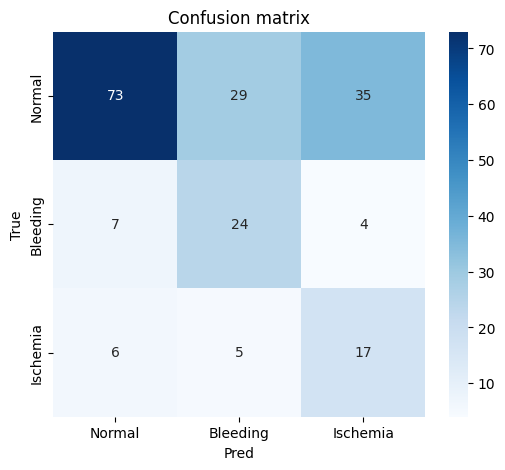

Confusion matrix:
 [[73 29 35]
 [ 7 24  4]
 [ 6  5 17]]


In [ ]:
y_true = []
y_pred = []
y_probs = []

for imgs, labs in test_ds:
    preds = model.predict(imgs, verbose=0)
    y_probs.extend(preds)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labs.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()
print("Confusion matrix:\n", cm)

In [ ]:
try:
    y_true_oh = label_binarize(y_true, classes=list(range(num_class)))
    aucs = []
    for i, cname in enumerate(class_names):
        auc = roc_auc_score(y_true_oh[:, i], y_probs[:, i])
        aucs.append(auc)
        print(f"AUC for class {cname}: {auc:.4f}")
except Exception as e:
    print("ROC calculation error:", e)

AUC for class Normal: 0.7119
AUC for class Bleeding: 0.7726
AUC for class Ischemia: 0.7755


In [ ]:
import math
def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))
    for i, idx in enumerate(idxs):
        path = paths[idx]
        img = safe_decode_png(path)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img = tf.image.resize(img, img_size)
        img = tf.squeeze(img).numpy()  # 2D
        # prepare for prediction
        inp = tf.expand_dims(tf.expand_dims(img, -1), 0)  # (1,H,W,1)
        probs = model.predict(inp, verbose=0)[0]
        pcls = np.argmax(probs)
        tcls = labels[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap='gray')
        color = "green" if int(pcls) == int(tcls) else "red"
        fname = os.path.basename(path)
        plt.title(f"{fname}\nT:{class_names[int(tcls)]} P:{class_names[int(pcls)]}\n{probs.round(3)}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


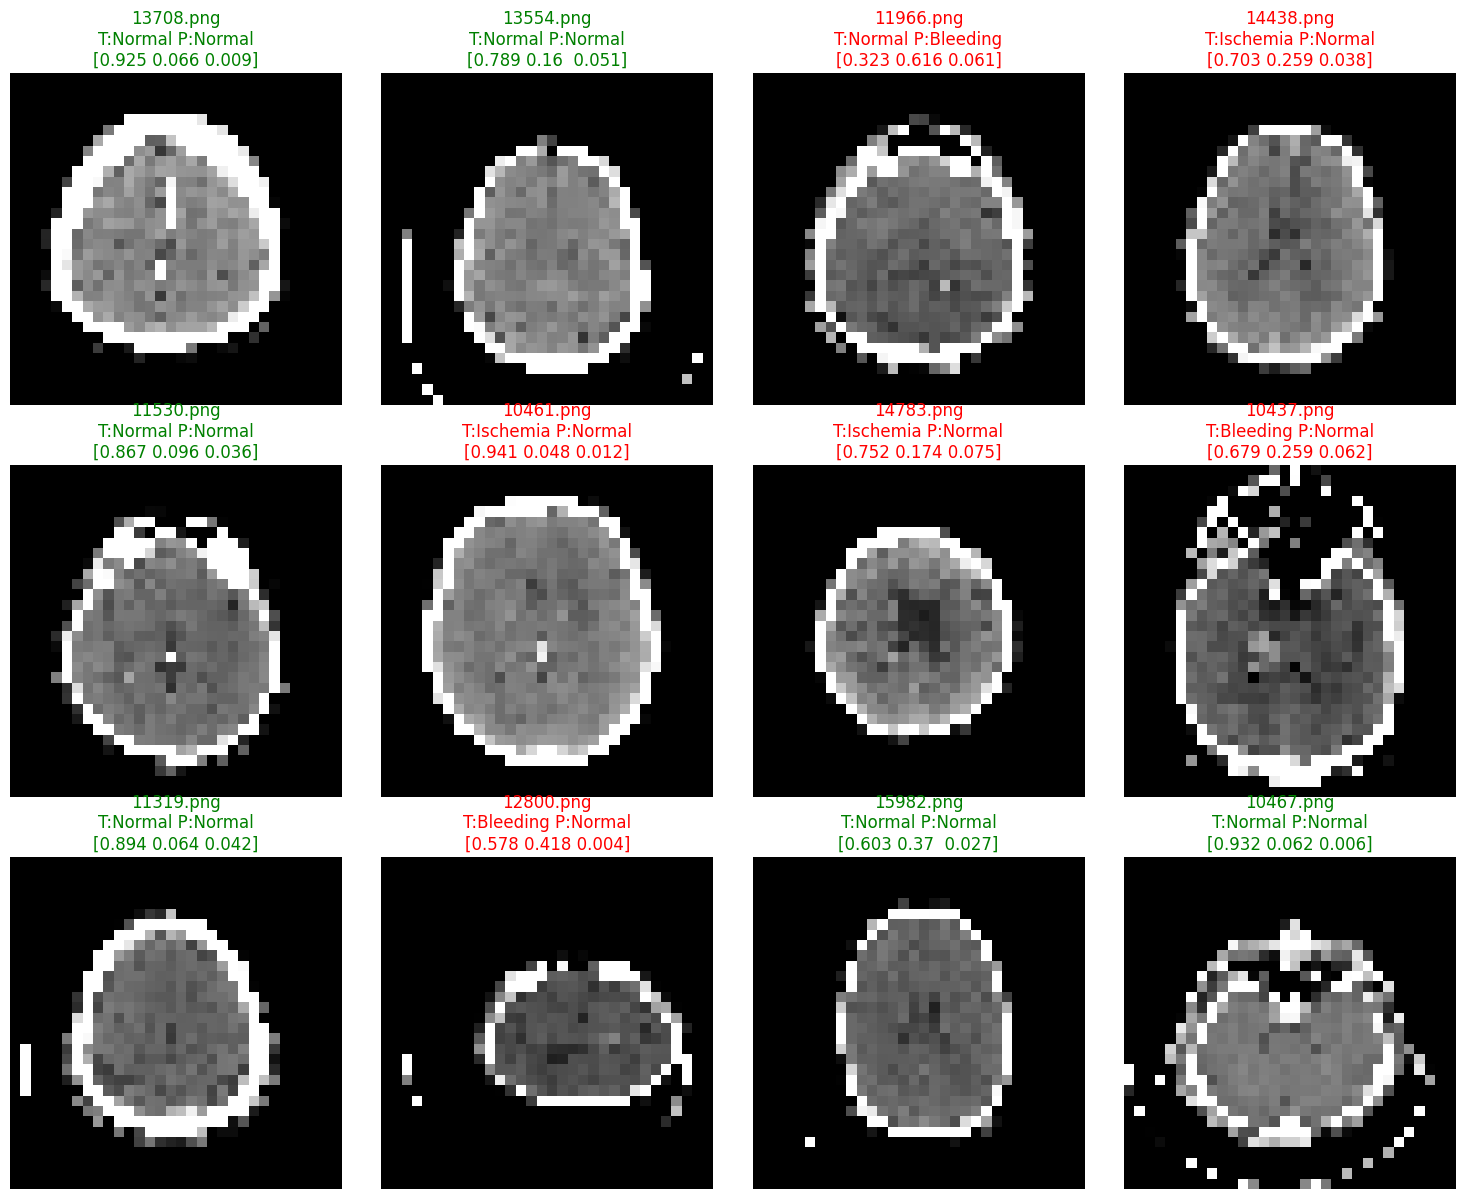

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

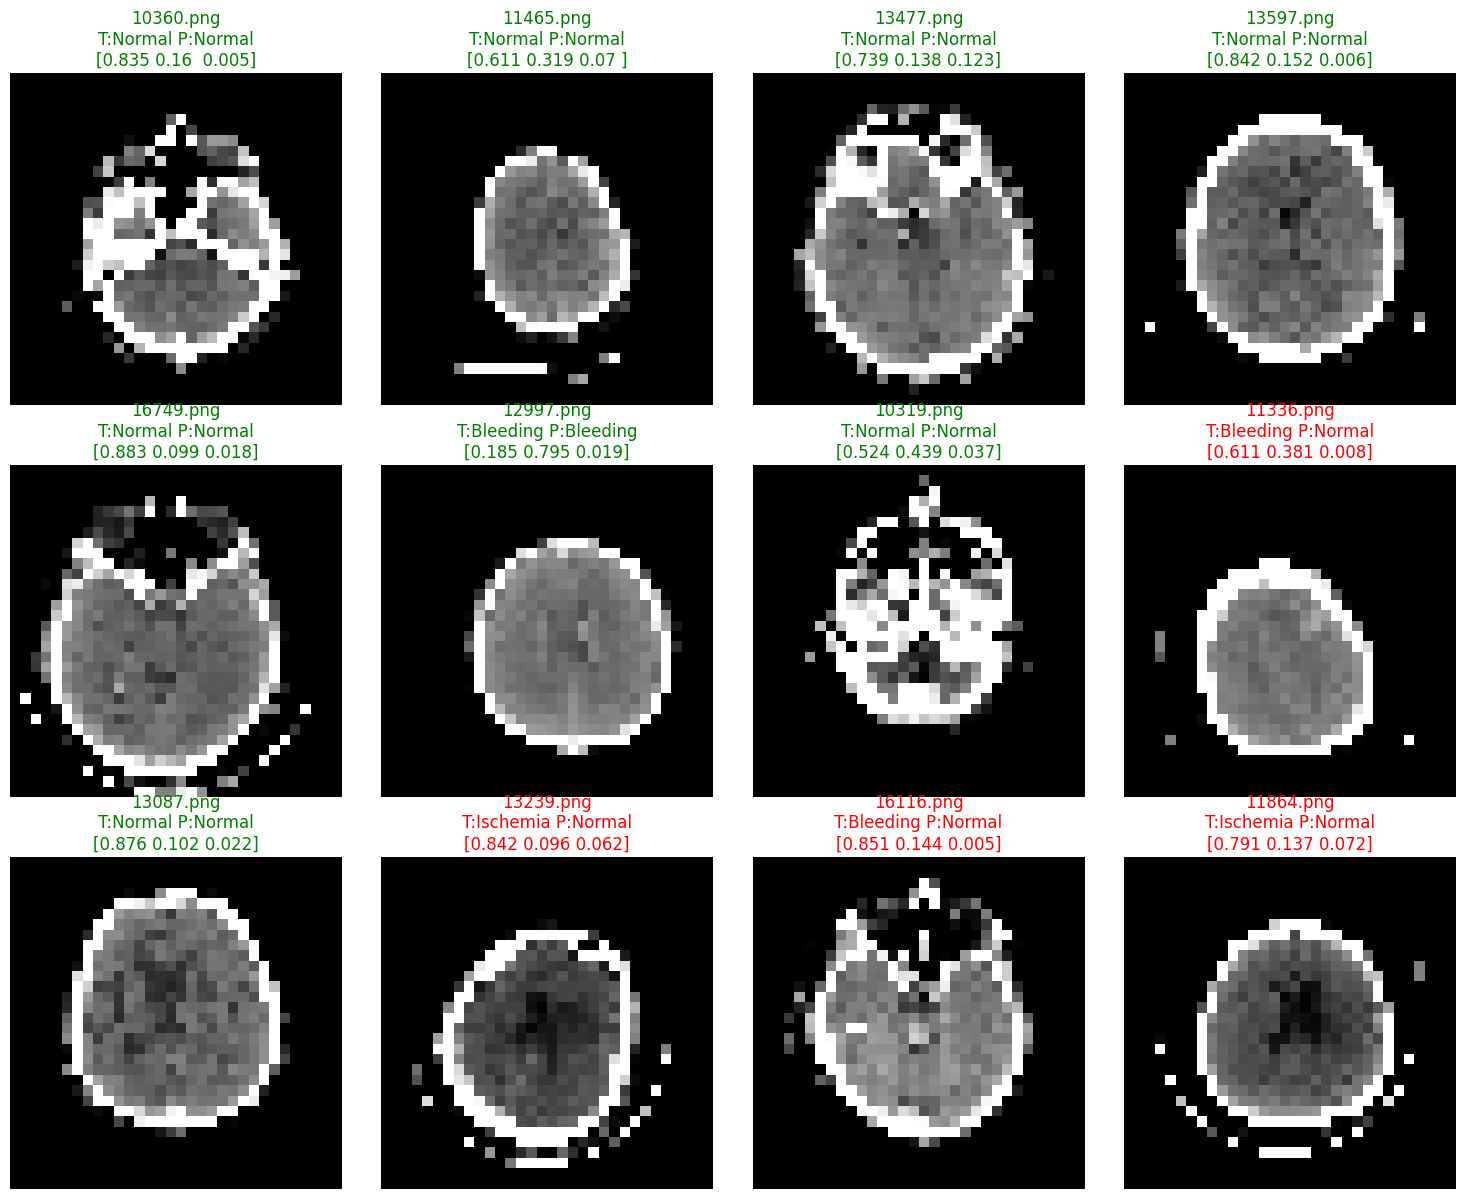

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

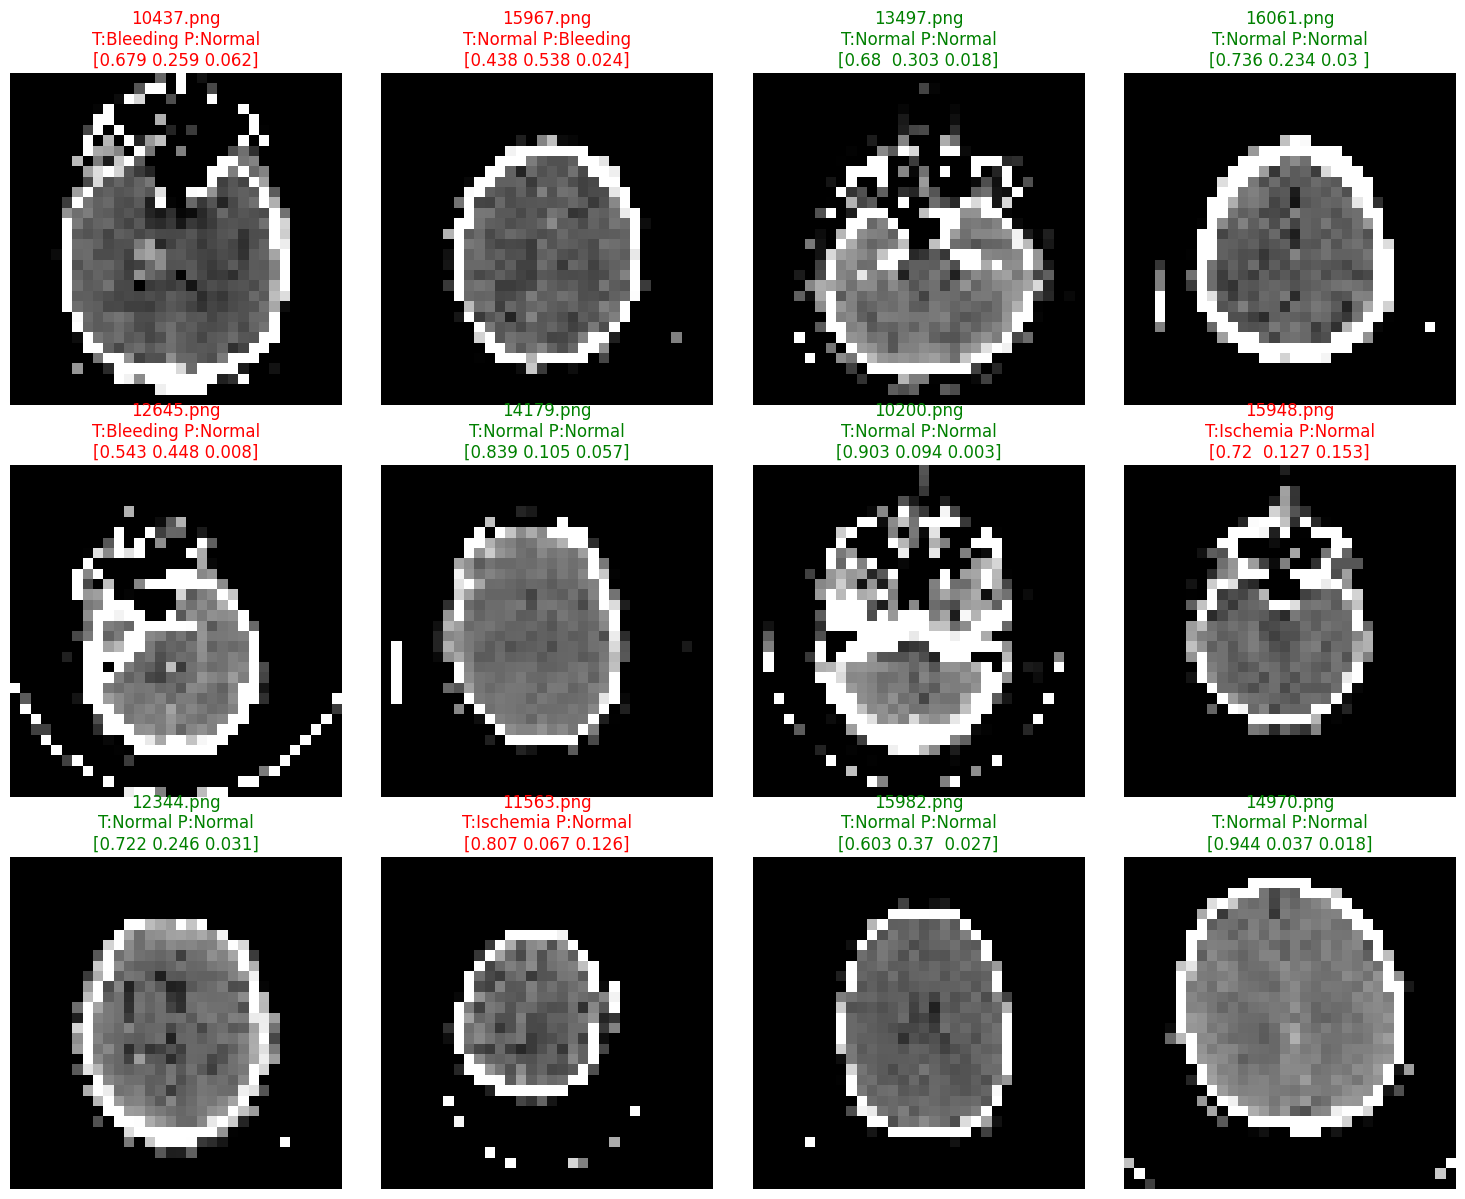

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

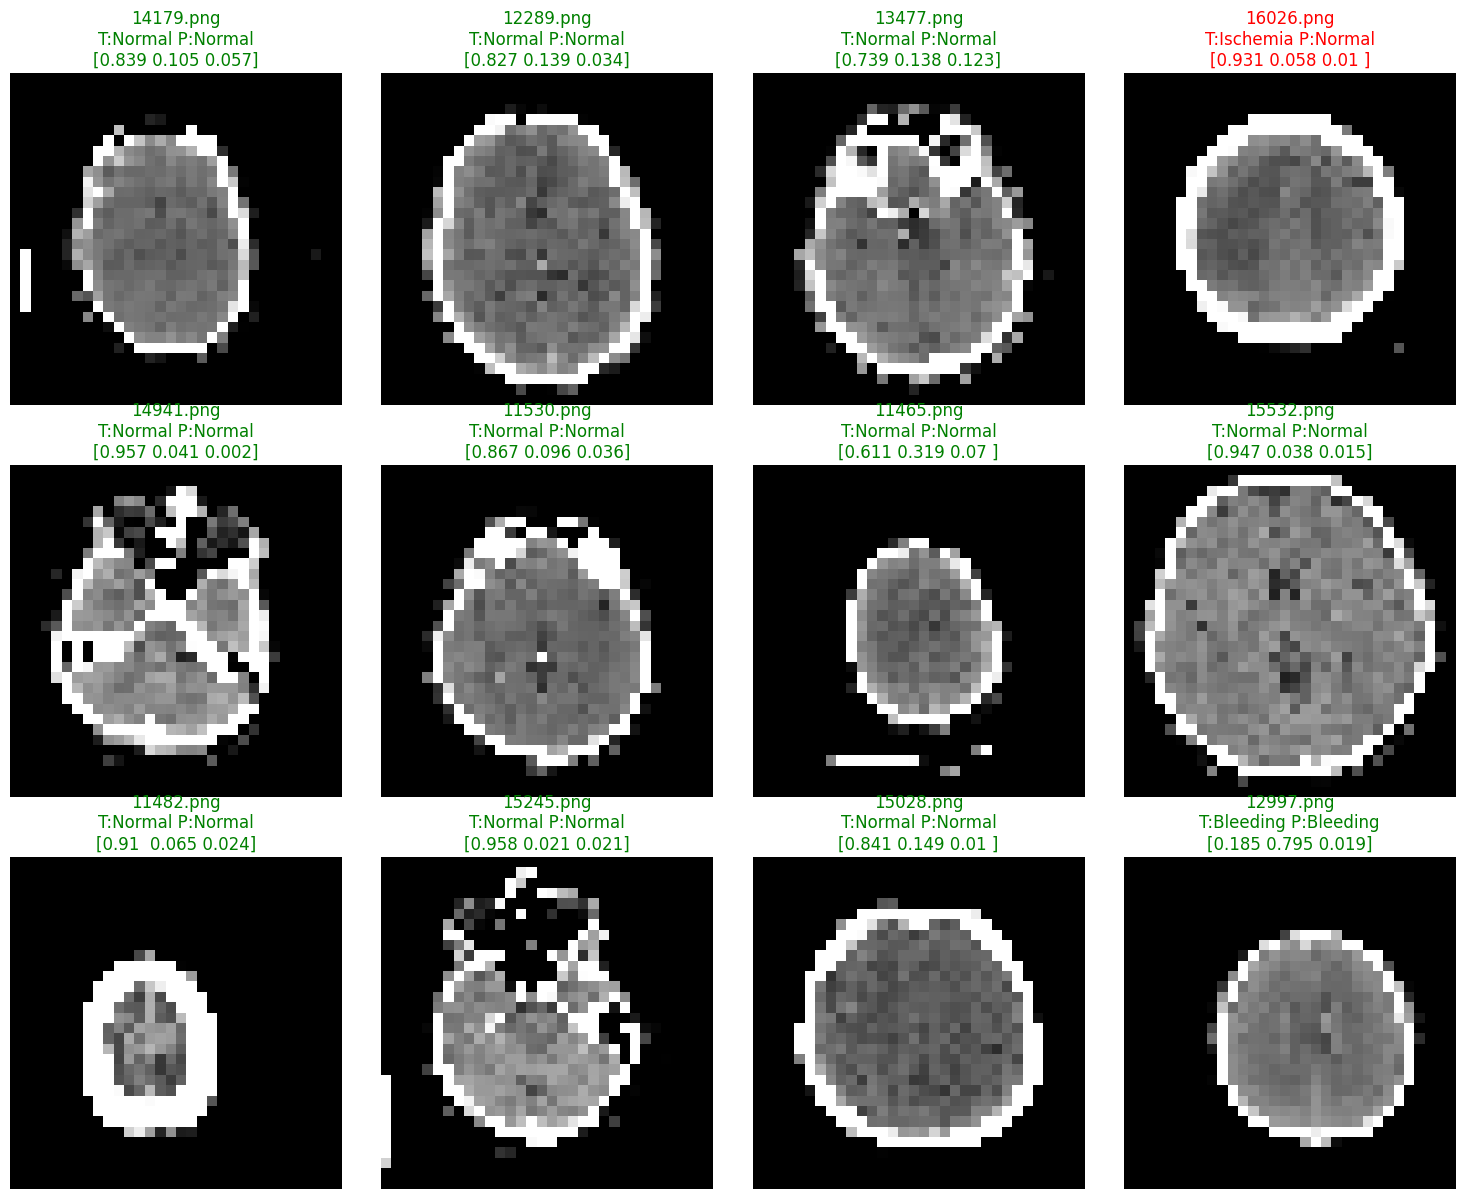

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

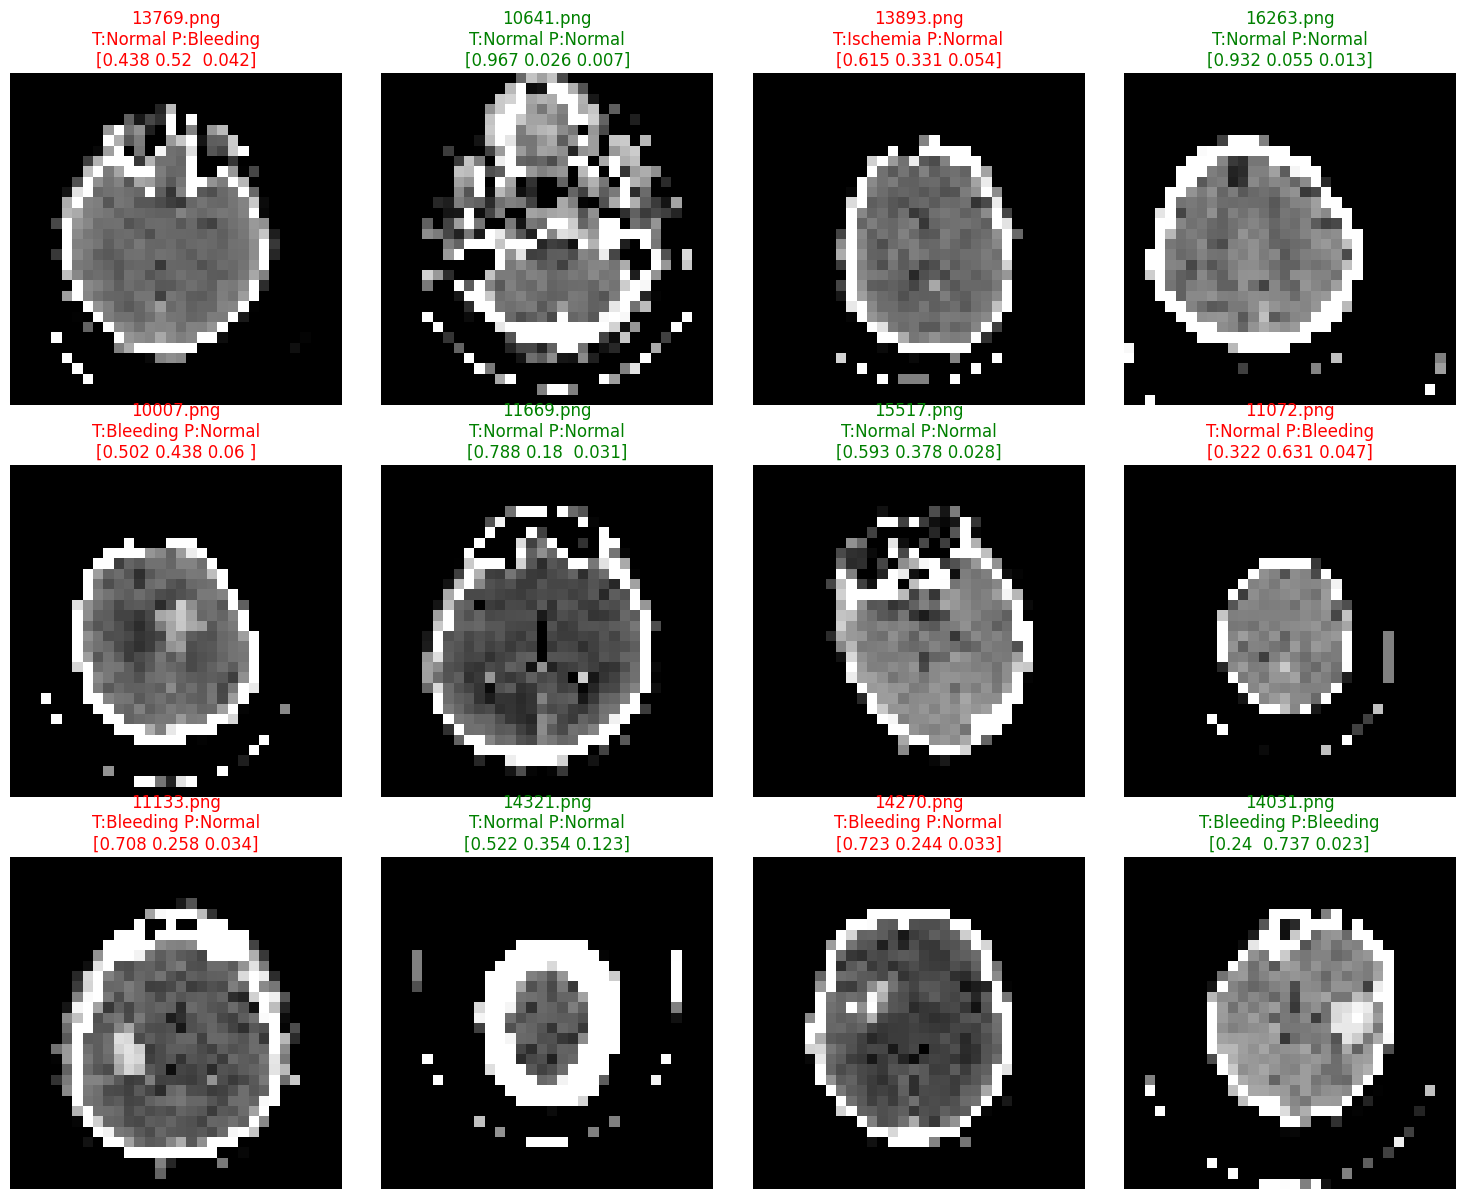

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

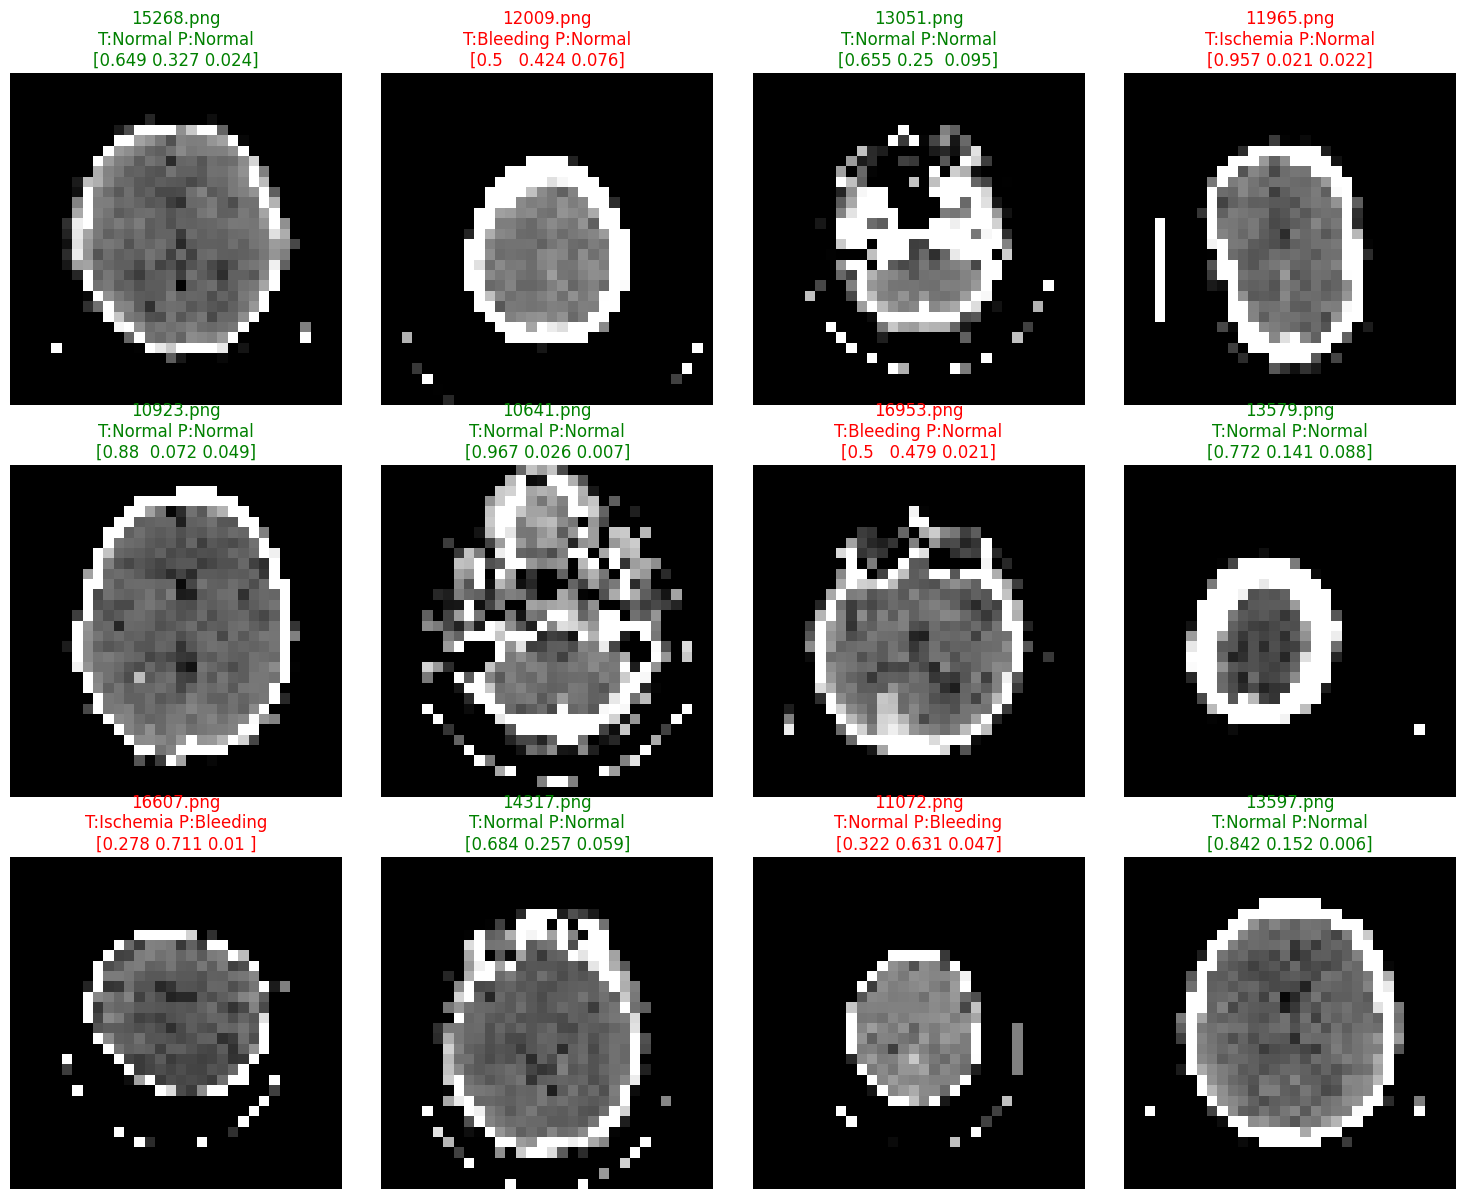

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

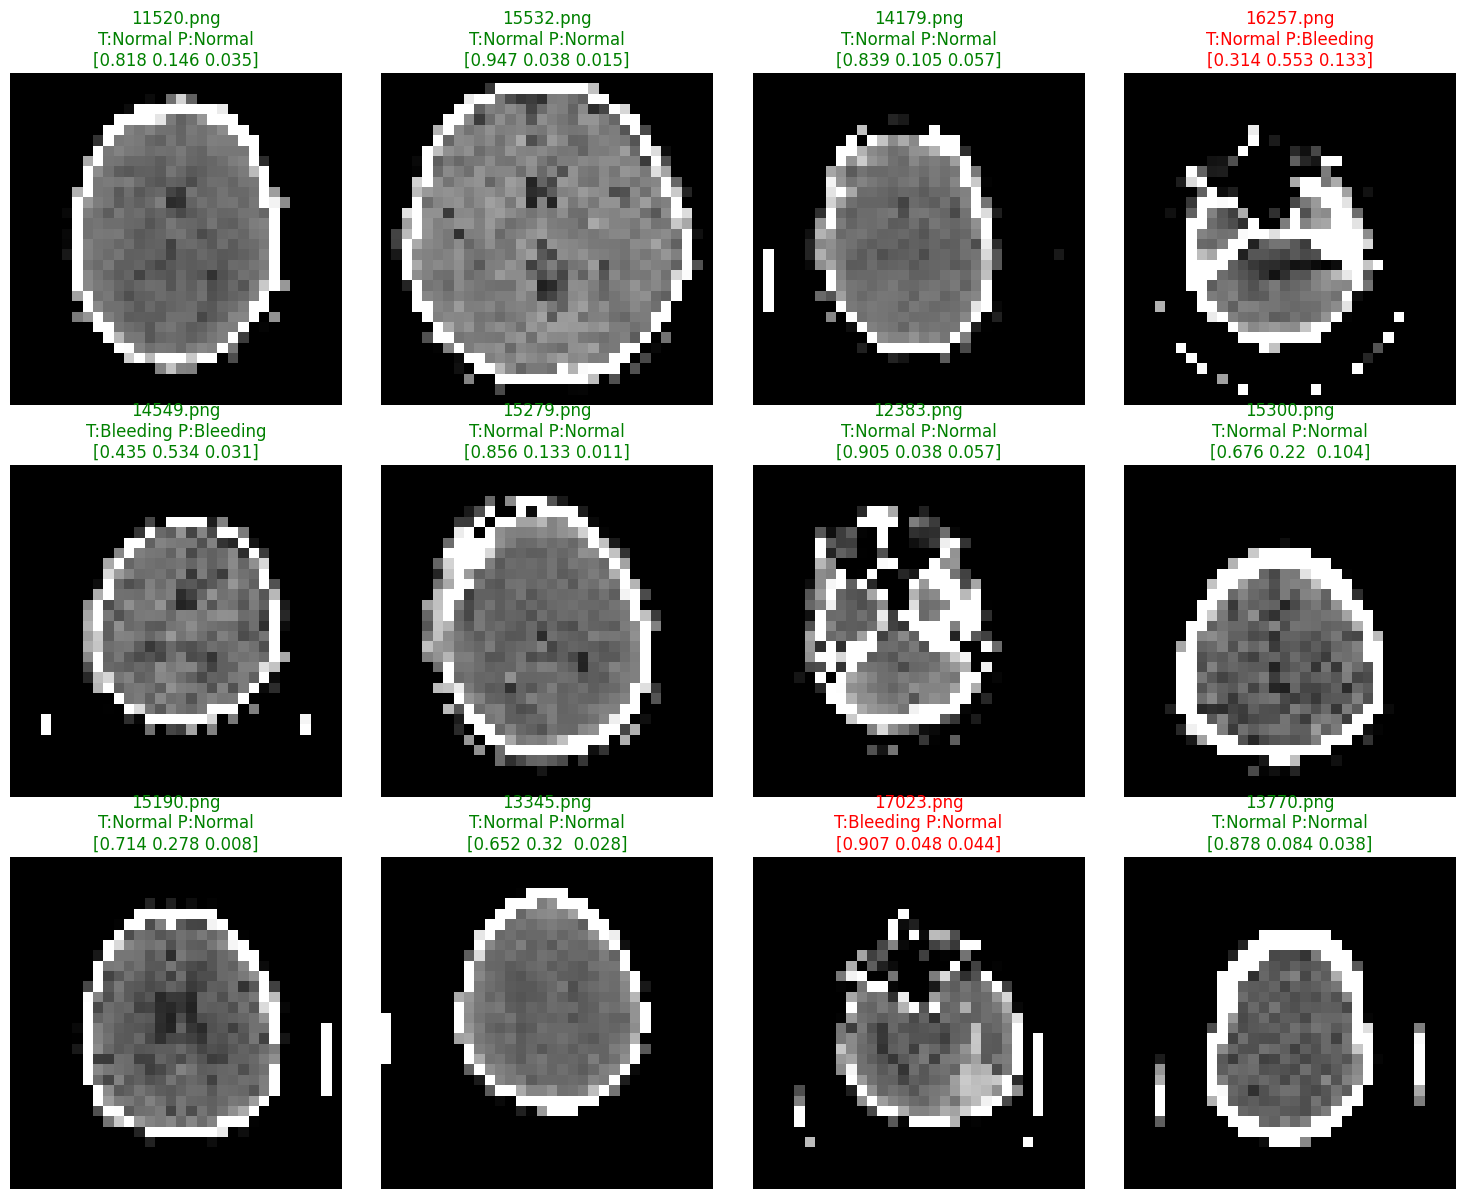

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

ОРИГИНАЛЬНАЯ АРХИТЕКТУРА С РАЗМЕРОМ 64

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

def build_lenet5(input_shape=(64, 64, 1), num_classes=3):
    inputs = layers.Input(shape=input_shape, name="input")

    x = layers.Conv2D(filters=6, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C1_conv")(inputs)

    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S2_pool")(x)

    x = layers.Conv2D(filters=16, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C3_conv")(x)

    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S4_pool")(x)

    x = layers.Conv2D(filters=120, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C5_conv")(x)

    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(84, activation=tf.nn.tanh, name="F6_dense")(x)

    outputs = layers.Dense(num_classes, activation='softmax', name="output")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="LeNet-5_classical")
    return model

model = build_lenet5()
model.summary()

Model: "LeNet-5_classical"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 64, 64, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1_conv (Conv2D)                │ (None, 60, 60, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_pool (AveragePooling2D)      │ (None, 30, 30, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_conv (Conv2D)                │ (None, 26, 26, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_pool (AveragePooling2D)      │ (None, 13, 13, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_conv (Conv2D)                │ (None, 9, 9, 120)      │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9720)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_dense (Dense)                │ (None, 84)             │       816,564 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 867,511 (3.31 MB)

 Trainable params: 867,511 (3.31 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=optimizers.SGD(learning_rate=0.01, momentum=0.9, weight_decay=0.0005),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])


In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

ckpt_path = "best_lenet_model.h5"
ckpt = ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
es = EarlyStopping(monitor="val_loss", mode="min", patience=8, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)


In [ ]:
history = model.fit(train_ds, validation_data=val_ds, epochs=200, class_weight=class_weights, callbacks=[ckpt, es, rlr], verbose=1)

Epoch 1/200


I0000 00:00:1764951670.979298     112 service.cc:148] XLA service 0x7ae370010130 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1764951670.980622     112 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1764951670.980647     112 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1764951671.285953     112 cuda_dnn.cc:529] Loaded cuDNN version 90300


10/72 ━━━━━━━━━━━━━━━━━━━━ 1s 16ms/step - accuracy: 0.3092 - loss: 1.1054

I0000 00:00:1764951674.792311     112 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


72/72 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step - accuracy: 0.4264 - loss: 1.0603
Epoch 1: val_accuracy improved from -inf to 0.51118, saving model to best_lenet_model.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 18s 188ms/step - accuracy: 0.4271 - loss: 1.0598 - val_accuracy: 0.5112 - val_loss: 1.0060 - learning_rate: 0.0100
Epoch 2/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5623 - loss: 0.9454
Epoch 2: val_accuracy improved from 0.51118 to 0.54370, saving model to best_lenet_model.h5


... (11 outputs left out)

72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 0.9732 - loss: 0.1031 - val_accuracy: 0.8018 - val_loss: 0.5944 - learning_rate: 0.0100
Epoch 20/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 0.9939 - loss: 0.0585
Epoch 20: val_accuracy improved from 0.80183 to 0.80386, saving model to best_lenet_model.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.9939 - loss: 0.0586 - val_accuracy: 0.8039 - val_loss: 0.6038 - learning_rate: 0.0100
Epoch 21/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9948 - loss: 0.0403
Epoch 21: val_accuracy did not improve from 0.80386
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 92ms/step - accuracy: 0.9948 - loss: 0.0403 - val_accuracy: 0.7967 - val_loss: 0.6420 - learning_rate: 0.0100
Epoch 22/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0252
Epoch 22: val_accuracy improved from 0.80386 to 0.81707, saving model to best_lenet_model.h5



Epoch 22: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 1.0000 - loss: 0.0252 - val_accuracy: 0.8171 - val_loss: 0.6331 - learning_rate: 0.0100
Epoch 23/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.9998 - loss: 0.0183
Epoch 23: val_accuracy did not improve from 0.81707
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 94ms/step - accuracy: 0.9998 - loss: 0.0183 - val_accuracy: 0.8079 - val_loss: 0.6354 - learning_rate: 0.0050
Epoch 24/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 0.0141
Epoch 24: val_accuracy improved from 0.81707 to 0.81911, saving model to best_lenet_model.h5


72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 91ms/step - accuracy: 1.0000 - loss: 0.0141 - val_accuracy: 0.8191 - val_loss: 0.6327 - learning_rate: 0.0050
Epoch 25/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 1.0000 - loss: 0.0120
Epoch 25: val_accuracy did not improve from 0.81911

Epoch 25: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 90ms/step - accuracy: 1.0000 - loss: 0.0121 - val_accuracy: 0.8110 - val_loss: 0.6433 - learning_rate: 0.0050
Epoch 26/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/step - accuracy: 1.0000 - loss: 0.0111
Epoch 26: val_accuracy did not improve from 0.81911
72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 90ms/step - accuracy: 1.0000 - loss: 0.0111 - val_accuracy: 0.8140 - val_loss: 0.6402 - learning_rate: 0.0025
Epoch 27/200
71/72 ━━━━━━━━━━━━━━━━━━━━ 0s 66ms/step - accuracy: 1.0000 - loss: 0.0104
Epoch 27: val_accuracy did not improve from 0.81911
72/72 ━━━━━━━━━━━━━━━━━━━━ 6s 89ms/step - accuracy: 1.0000 - loss: 0.0104 - val_accur

In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 207ms/step - accuracy: 0.6295 - loss: 1.0792

Test Loss: 1.1163
Test Accuracy: 0.6400


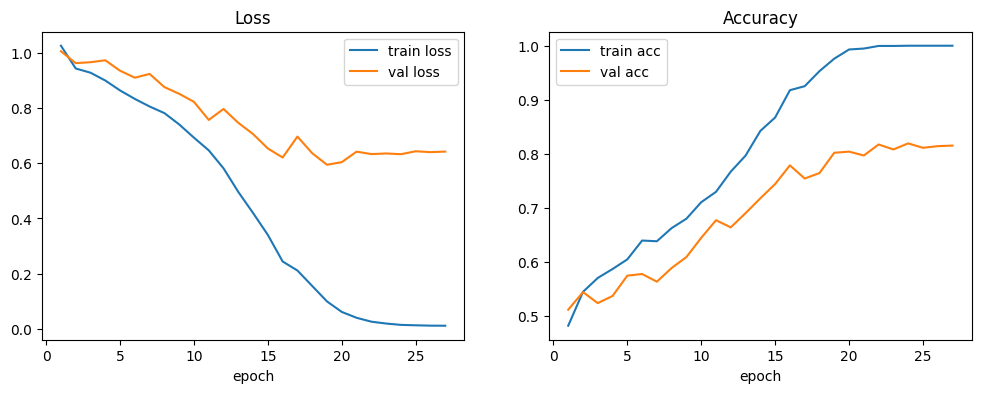

In [ ]:
def plot_history(history):
    h = history.history
    epochs = range(1, len(h['loss'])+1)

    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, h['loss'], label='train loss')
    plt.plot(epochs, h['val_loss'], label='val loss')
    plt.xlabel('epoch'); plt.legend(); plt.title('Loss')

    plt.subplot(1,2,2)
    plt.plot(epochs, h['accuracy'], label='train acc')
    plt.plot(epochs, h.get('val_accuracy', []), label='val acc')
    plt.xlabel('epoch'); plt.legend(); plt.title('Accuracy')

    plt.show()

plot_history(history)


Classification Report:
              precision    recall  f1-score   support

      Normal     0.8673    0.6204    0.7234       137
    Bleeding     0.4706    0.6857    0.5581        35
    Ischemia     0.3725    0.6786    0.4810        28

    accuracy                         0.6400       200
   macro avg     0.5702    0.6616    0.5875       200
weighted avg     0.7286    0.6400    0.6605       200



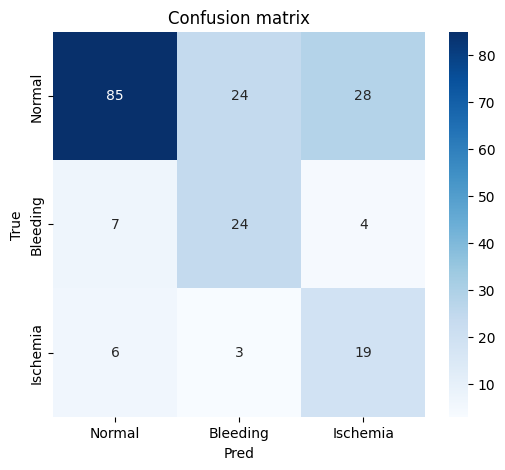

Confusion matrix:
 [[85 24 28]
 [ 7 24  4]
 [ 6  3 19]]


In [ ]:
y_true = []
y_pred = []
y_probs = []

for imgs, labs in test_ds:
    preds = model.predict(imgs, verbose=0)
    y_probs.extend(preds)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labs.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()
print("Confusion matrix:\n", cm)

In [ ]:
try:
    y_true_oh = label_binarize(y_true, classes=list(range(num_class)))
    aucs = []
    for i, cname in enumerate(class_names):
        auc = roc_auc_score(y_true_oh[:, i], y_probs[:, i])
        aucs.append(auc)
        print(f"AUC for class {cname}: {auc:.4f}")
except Exception as e:
    print("ROC calculation error:", e)

AUC for class Normal: 0.7894
AUC for class Bleeding: 0.8426
AUC for class Ischemia: 0.8079


In [ ]:
import math
def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))
    for i, idx in enumerate(idxs):
        path = paths[idx]
        img = safe_decode_png(path)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img = tf.image.resize(img, img_size)
        img = tf.squeeze(img).numpy()  # 2D
        inp = tf.expand_dims(tf.expand_dims(img, -1), 0)  # (1,H,W,1)
        probs = model.predict(inp, verbose=0)[0]
        pcls = np.argmax(probs)
        tcls = labels[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap='gray')
        color = "green" if int(pcls) == int(tcls) else "red"
        fname = os.path.basename(path)
        plt.title(f"{fname}\nT:{class_names[int(tcls)]} P:{class_names[int(pcls)]}\n{probs.round(3)}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


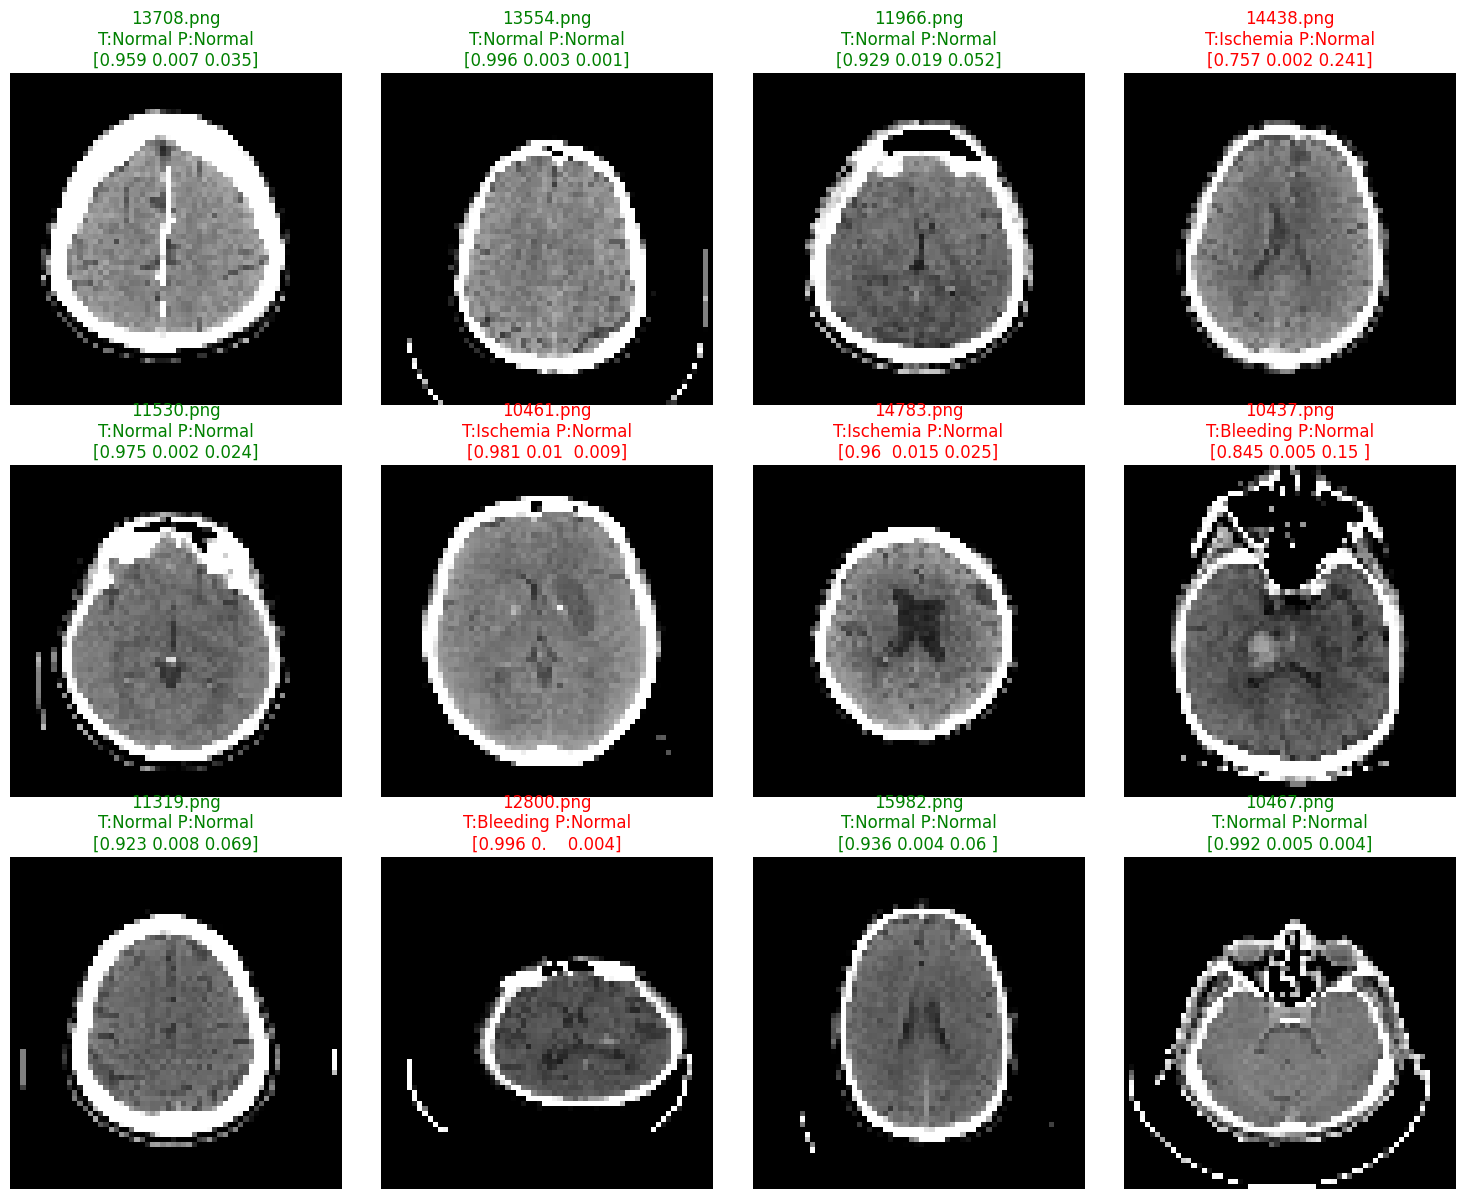

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

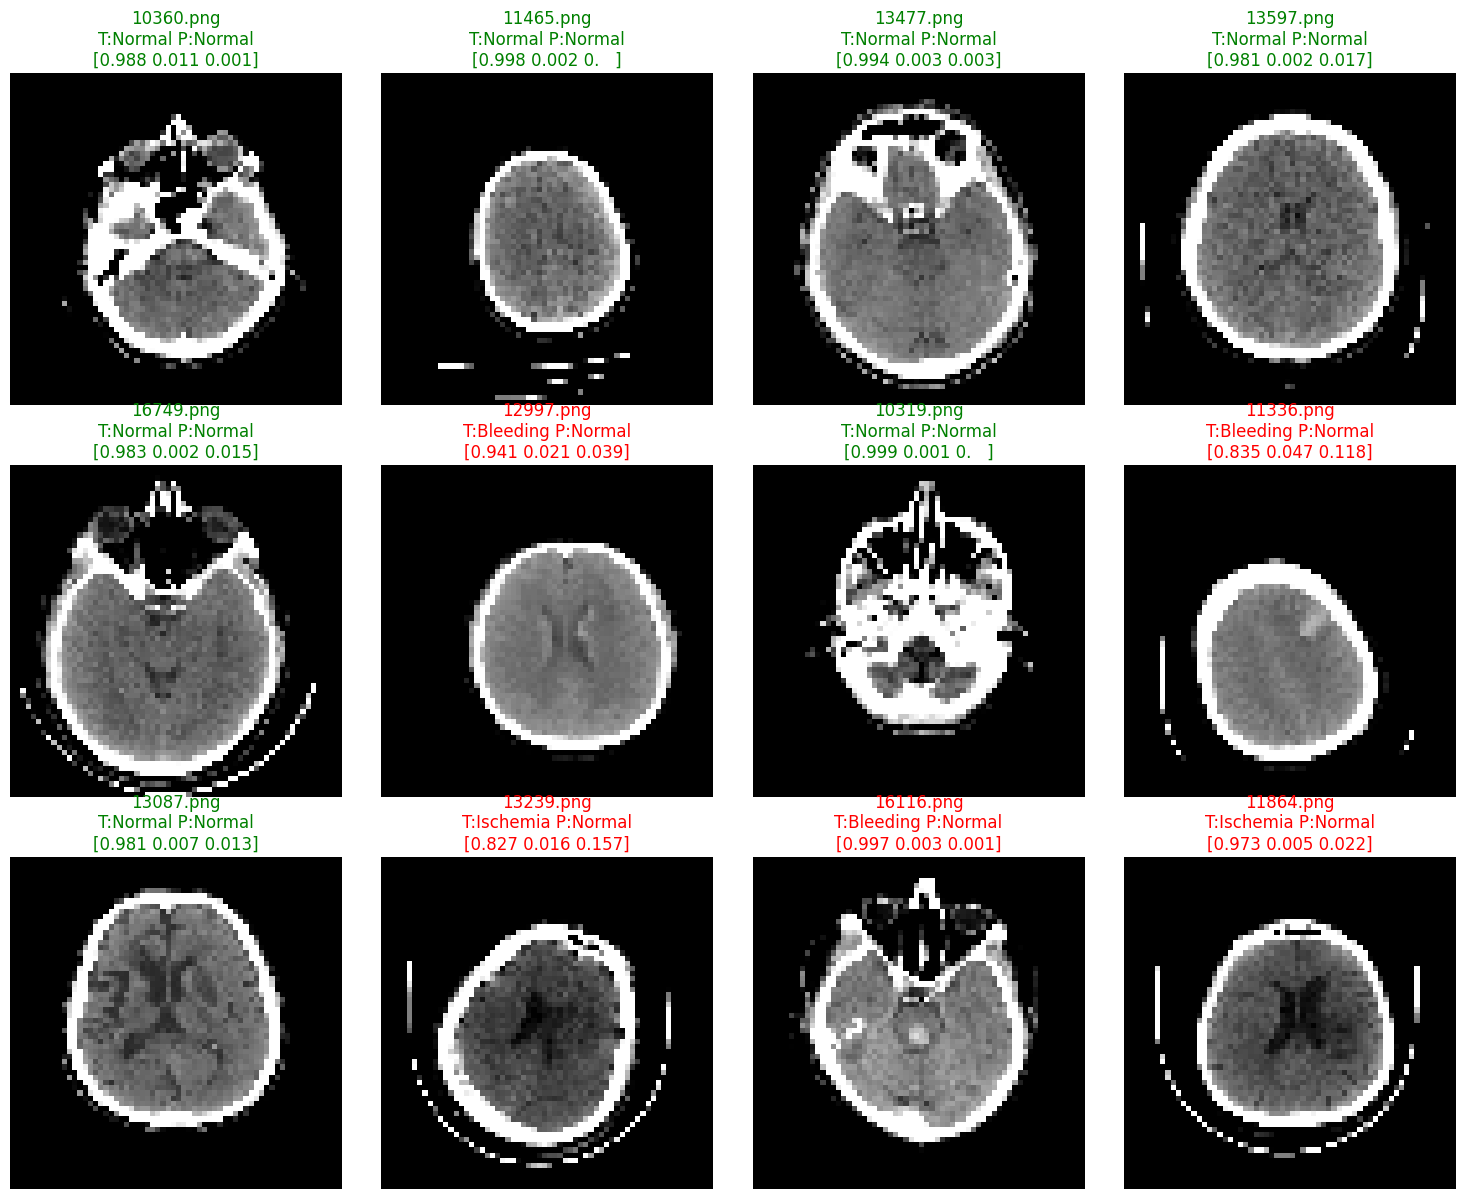

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

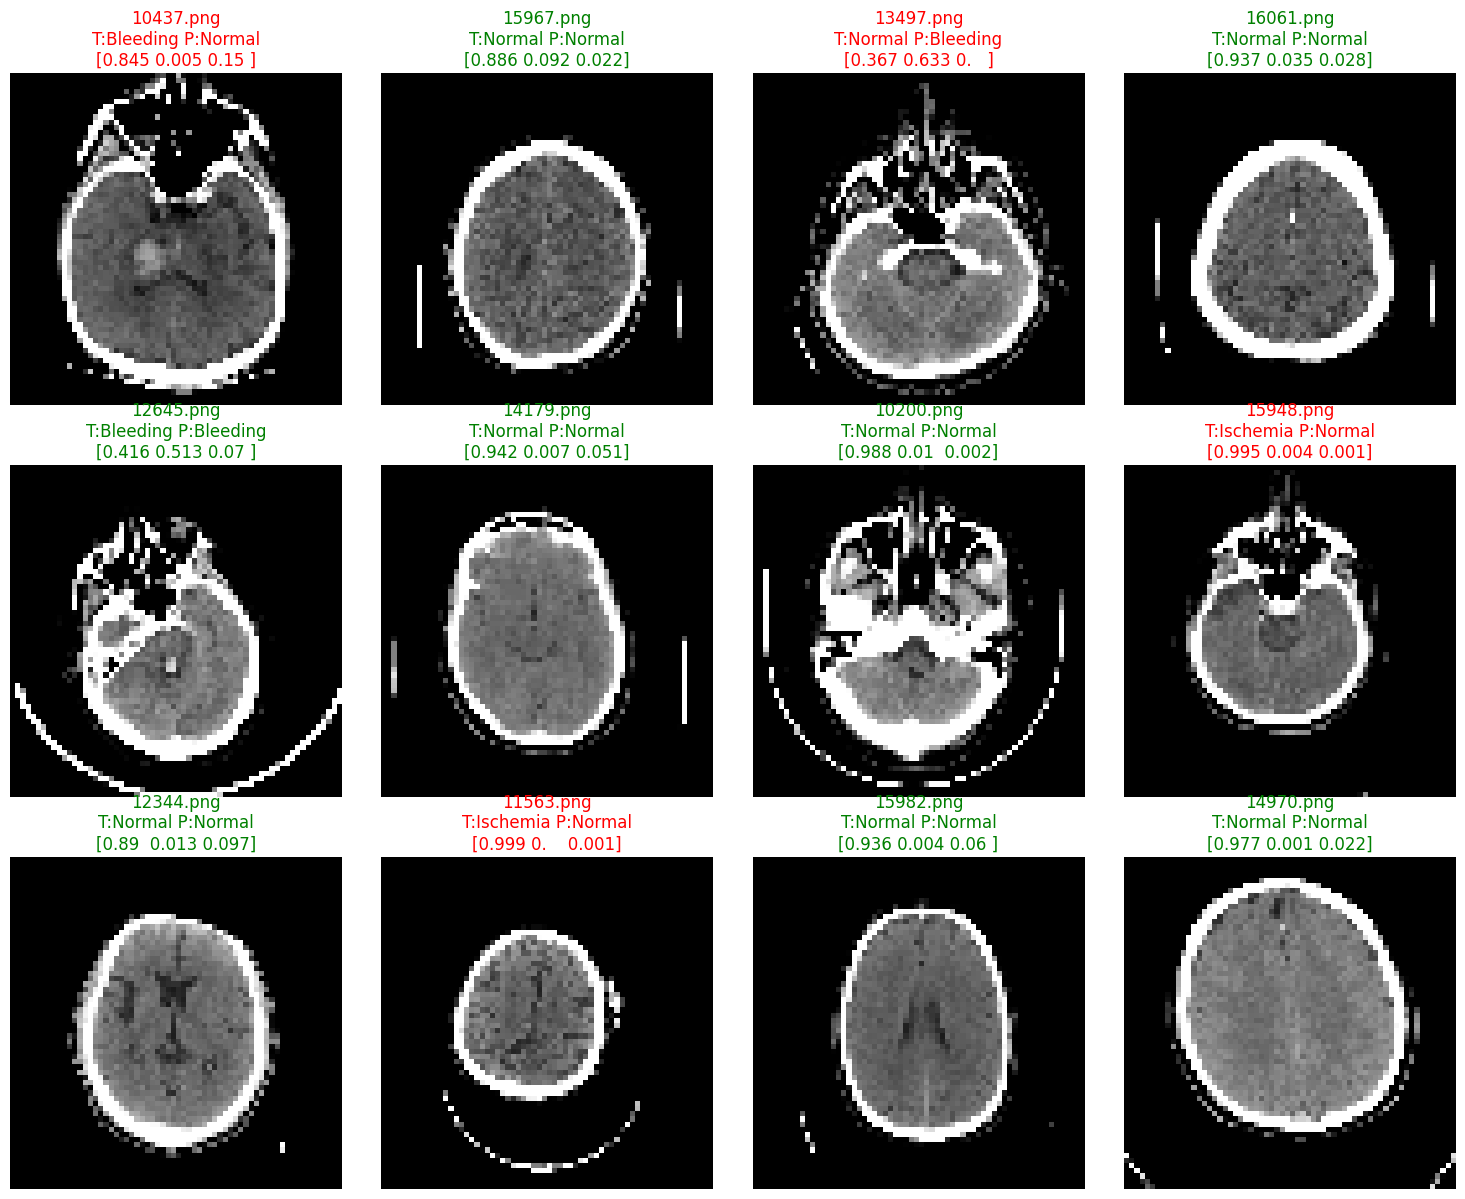

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

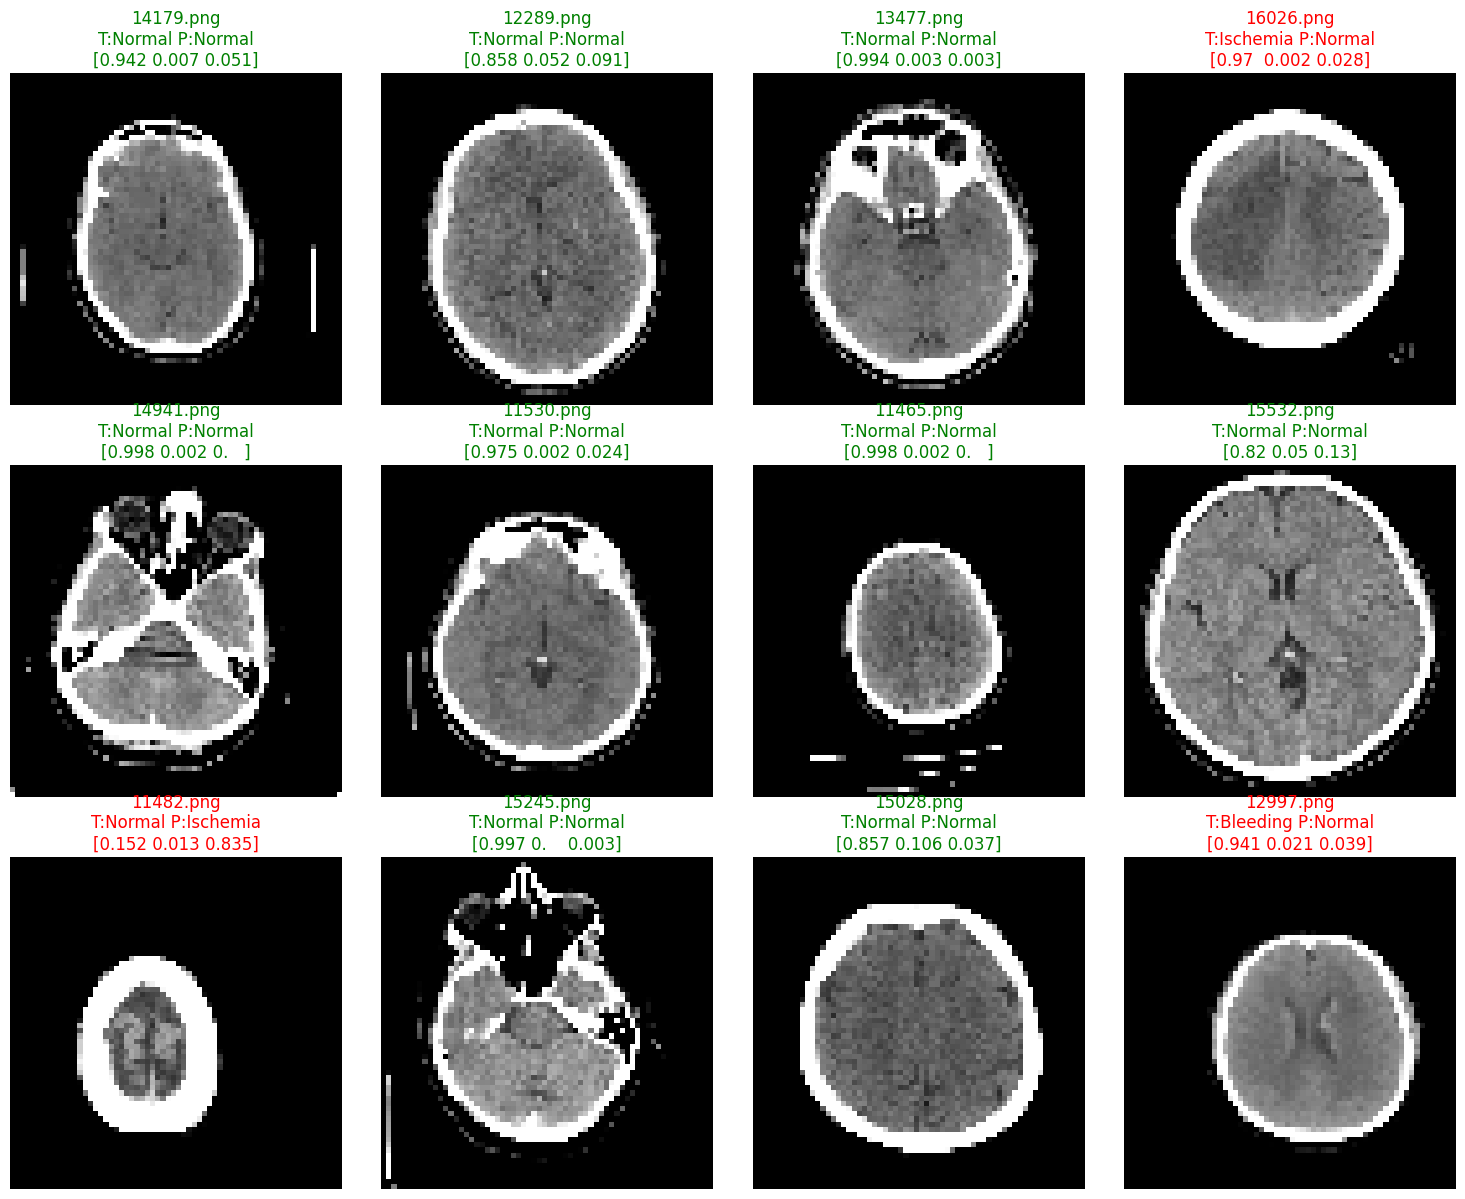

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

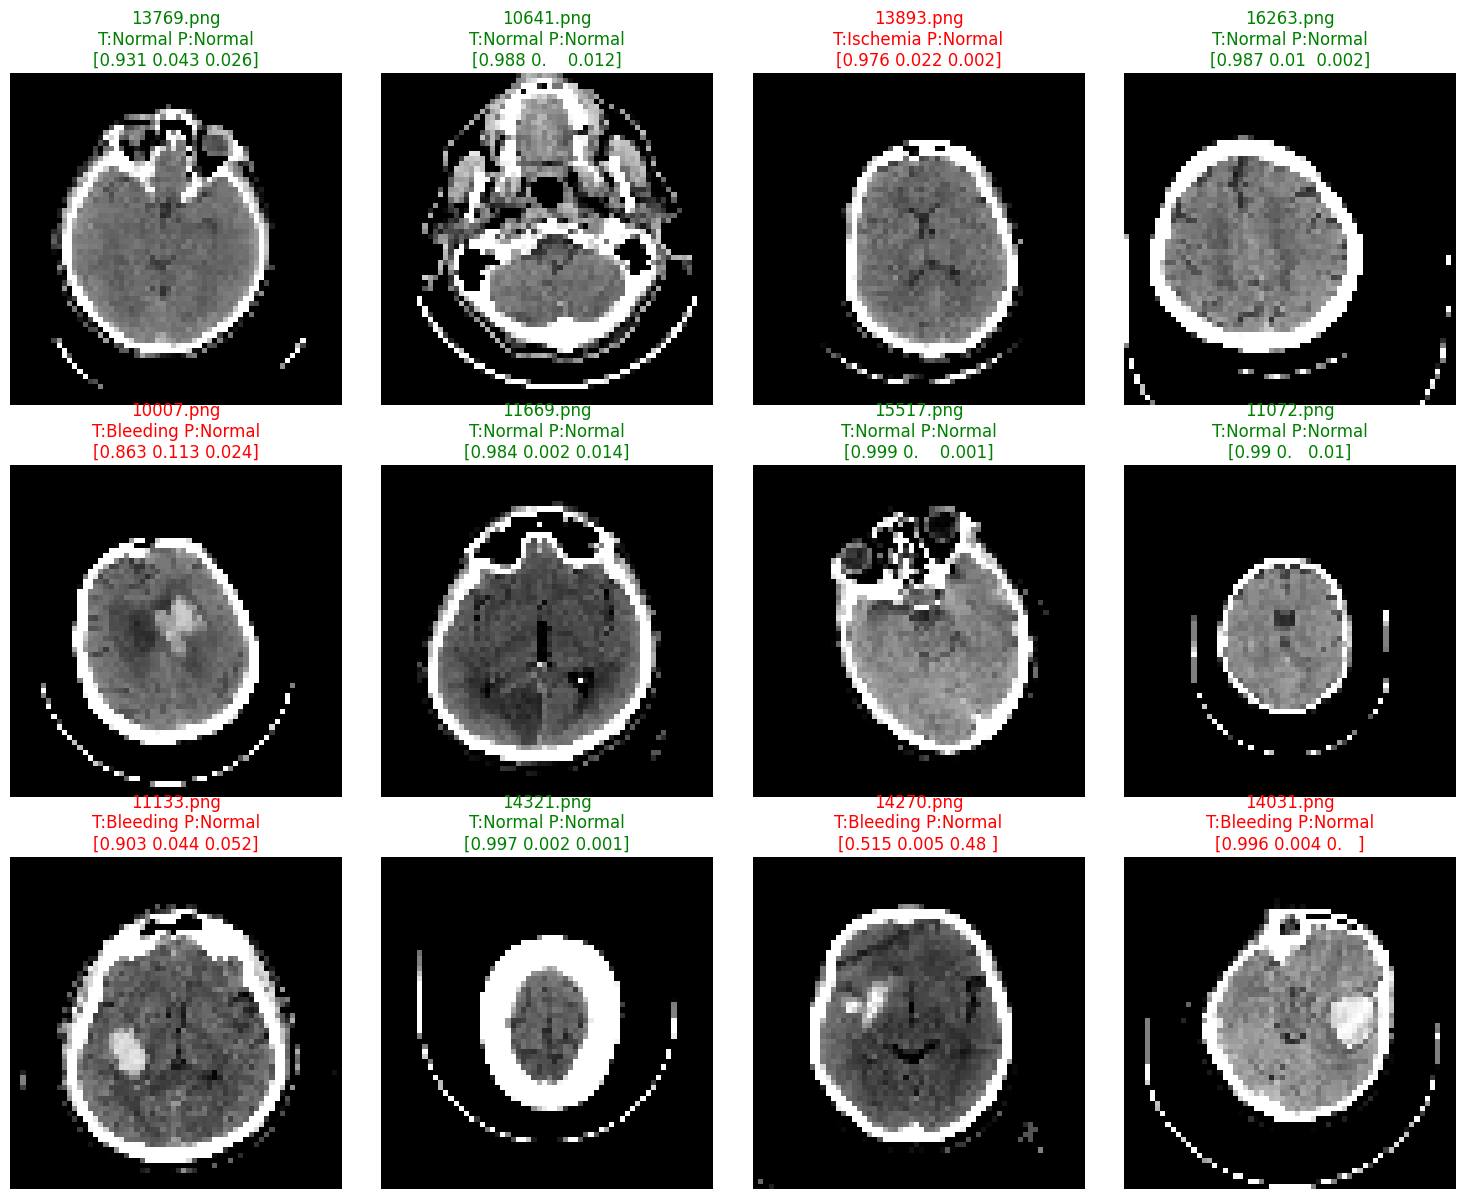

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

ОРИГИНАЛЬНАЯ АРХИТЕКТУРА С РАЗМЕРОМ 128

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models, optimizers

def build_lenet5(input_shape=(128, 128, 1), num_classes=3):
    inputs = layers.Input(shape=input_shape, name="input")

    # C1: conv -> tanh
    x = layers.Conv2D(filters=6, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C1_conv")(inputs)

    # S2: avg pool (subsampling)
    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S2_pool")(x)

    # C3: conv (16 kernels of size 5)
    x = layers.Conv2D(filters=16, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C3_conv")(x)

    # S4: avg pool
    x = layers.AveragePooling2D(pool_size=2, strides=2, padding='valid', name="S4_pool")(x)

    # C5: conv 120 filters of size 5 (in original this becomes 1x1x120 for 32->28->14->10->5->1 chain)
    x = layers.Conv2D(filters=120, kernel_size=5, strides=1, padding='valid', activation=tf.nn.tanh, name="C5_conv")(x)

    # Flatten + Fully connected layers
    x = layers.Flatten(name="flatten")(x)
    x = layers.Dense(84, activation=tf.nn.tanh, name="F6_dense")(x)

    # Output layer
    outputs = layers.Dense(num_classes, activation='softmax', name="output")(x)

    model = models.Model(inputs=inputs, outputs=outputs, name="LeNet-5_classical")
    return model

model = build_lenet5()
model.summary()

Model: "LeNet-5_classical"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input (InputLayer)              │ (None, 128, 128, 1)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C1_conv (Conv2D)                │ (None, 124, 124, 6)    │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S2_pool (AveragePooling2D)      │ (None, 62, 62, 6)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C3_conv (Conv2D)                │ (None, 58, 58, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ S4_pool (AveragePooling2D)      │ (None, 29, 29, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ C5_conv (Conv2D)                │ (None, 25, 25, 120)    │        48,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 75000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ F6_dense (Dense)                │ (None, 84)             │     6,300,084 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output (Dense)                  │ (None, 3)              │           255 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,351,031 (24.23 MB)

 Trainable params: 6,351,031 (24.23 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=optimizers.SGD(learning_rate=0.01, momentum=0.9),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'])

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

ckpt_path = "best_lenet_model.h5"
ckpt = ModelCheckpoint(ckpt_path, monitor="val_accuracy", save_best_only=True, mode="max", verbose=1)
es = EarlyStopping(monitor="val_loss", mode="min", patience=8, restore_best_weights=True, verbose=1)
rlr = ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-7, verbose=1)

In [ ]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=200,
    class_weight=class_weights,
    callbacks=[ckpt, es, rlr],
    verbose=1)

Epoch 1/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.4538 - loss: 1.0501
Epoch 1: val_accuracy improved from -inf to 0.53760, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 9s 184ms/step - accuracy: 0.4549 - loss: 1.0492 - val_accuracy: 0.5376 - val_loss: 0.9646 - learning_rate: 0.0100
Epoch 2/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.6006 - loss: 0.8828
Epoch 2: val_accuracy improved from 0.53760 to 0.57317, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.6006 - loss: 0.8827 - val_accuracy: 0.5732 - val_loss: 0.9059 - learning_rate: 0.0100
Epoch 3/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.6539 - loss: 0.7963
Epoch 3: val_accuracy improved from 0.57317 to 0.59146, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 197ms/step - accuracy: 0.6539 - loss: 0.7962 - val_accuracy: 0.5915 - val_loss: 0.9360 - learning_rate: 0.0100
Epoch 4/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.7201 - loss: 0.6800
Epoch 4: val_accuracy improved from 0.59146 to 0.63008, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 168ms/step - accuracy: 0.7196 - loss: 0.6806 - val_accuracy: 0.6301 - val_loss: 0.8609 - learning_rate: 0.0100
Epoch 5/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.7336 - loss: 0.6449
Epoch 5: val_accuracy did not improve from 0.63008
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 164ms/step - accuracy: 0.7337 - loss: 0.6447 - val_accuracy: 0.6189 - val_loss: 0.8848 - learning_rate: 0.0100
Epoch 6/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.7828 - loss: 0.5436
Epoch 6: val_accuracy improved from 0.63008 to 0.66159, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.7826 - loss: 0.5440 - val_accuracy: 0.6616 - val_loss: 0.8518 - learning_rate: 0.0100
Epoch 7/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step - accuracy: 0.8121 - loss: 0.4790
Epoch 7: val_accuracy did not improve from 0.66159
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 161ms/step - accuracy: 0.8118 - loss: 0.4796 - val_accuracy: 0.6524 - val_loss: 0.8668 - learning_rate: 0.0100
Epoch 8/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.8467 - loss: 0.3935
Epoch 8: val_accuracy improved from 0.66159 to 0.66667, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.8462 - loss: 0.3945 - val_accuracy: 0.6667 - val_loss: 0.8849 - learning_rate: 0.0100
Epoch 9/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step - accuracy: 0.8692 - loss: 0.3528
Epoch 9: val_accuracy did not improve from 0.66667

Epoch 9: ReduceLROnPlateau reducing learning rate to 0.004999999888241291.
36/36 ━━━━━━━━━━━━━━━━━━━━ 7s 191ms/step - accuracy: 0.8690 - loss: 0.3531 - val_accuracy: 0.6555 - val_loss: 0.9266 - learning_rate: 0.0100
Epoch 10/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9027 - loss: 0.2705
Epoch 10: val_accuracy improved from 0.66667 to 0.67378, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.9028 - loss: 0.2703 - val_accuracy: 0.6738 - val_loss: 0.8989 - learning_rate: 0.0050
Epoch 11/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9603 - loss: 0.1683
Epoch 11: val_accuracy improved from 0.67378 to 0.70224, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.9600 - loss: 0.1686 - val_accuracy: 0.7022 - val_loss: 0.8919 - learning_rate: 0.0050
Epoch 12/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9682 - loss: 0.1326
Epoch 12: val_accuracy improved from 0.70224 to 0.70732, saving model to best_lenet_model.h5



Epoch 12: ReduceLROnPlateau reducing learning rate to 0.0024999999441206455.
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 166ms/step - accuracy: 0.9681 - loss: 0.1328 - val_accuracy: 0.7073 - val_loss: 0.8973 - learning_rate: 0.0050
Epoch 13/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step - accuracy: 0.9824 - loss: 0.1023
Epoch 13: val_accuracy did not improve from 0.70732
36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 163ms/step - accuracy: 0.9825 - loss: 0.1022 - val_accuracy: 0.7033 - val_loss: 0.9194 - learning_rate: 0.0025
Epoch 14/200
36/36 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step - accuracy: 0.9941 - loss: 0.0759
Epoch 14: val_accuracy improved from 0.70732 to 0.71037, saving model to best_lenet_model.h5


36/36 ━━━━━━━━━━━━━━━━━━━━ 6s 167ms/step - accuracy: 0.9940 - loss: 0.0759 - val_accuracy: 0.7104 - val_loss: 0.9364 - learning_rate: 0.0025
Epoch 14: early stopping
Restoring model weights from the end of the best epoch: 6.


In [ ]:
test_loss, test_acc = model.evaluate(test_ds, verbose=1)
print(f"\nTest Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_acc:.4f}")

4/4 ━━━━━━━━━━━━━━━━━━━━ 1s 182ms/step - accuracy: 0.4911 - loss: 1.1067

Test Loss: 1.1037
Test Accuracy: 0.5000


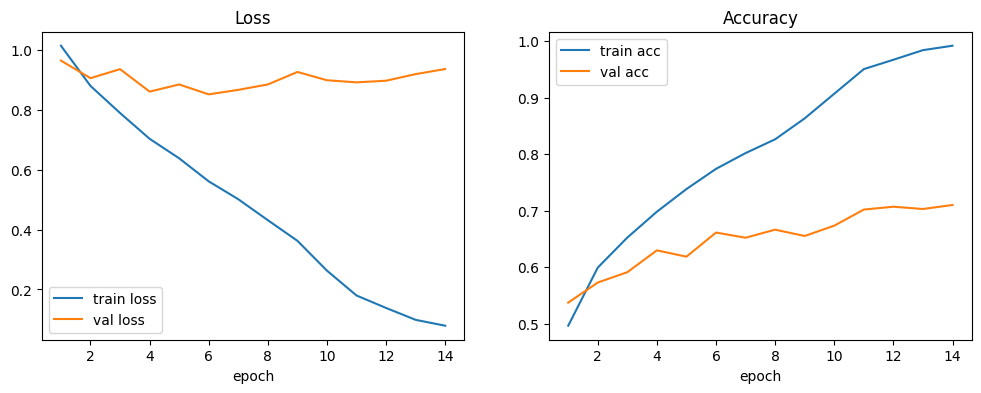

In [ ]:
def plot_history(history):
    h = history.history
    epochs = range(1, len(h['loss'])+1)

    plt.figure(figsize=(12,4))
    plt.subplot(1,2,1)
    plt.plot(epochs, h['loss'], label='train loss')
    plt.plot(epochs, h['val_loss'], label='val loss')
    plt.xlabel('epoch'); plt.legend(); plt.title('Loss')

    plt.subplot(1,2,2)
    plt.plot(epochs, h['accuracy'], label='train acc')
    plt.plot(epochs, h.get('val_accuracy', []), label='val acc')
    plt.xlabel('epoch'); plt.legend(); plt.title('Accuracy')

    plt.show()

plot_history(history)


Classification Report:
              precision    recall  f1-score   support

      Normal     0.7500    0.4818    0.5867       137
    Bleeding     0.3542    0.4857    0.4096        35
    Ischemia     0.2656    0.6071    0.3696        28

    accuracy                         0.5000       200
   macro avg     0.4566    0.5249    0.4553       200
weighted avg     0.6129    0.5000    0.5253       200



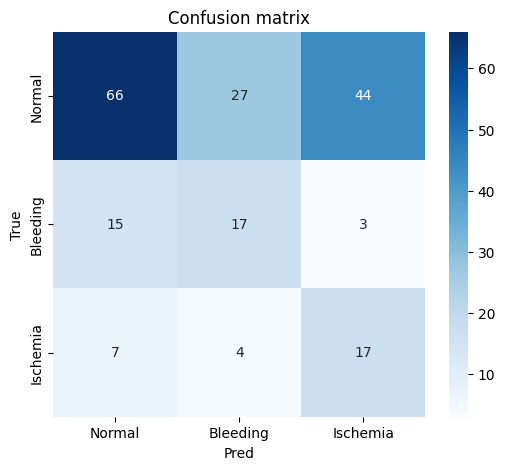

Confusion matrix:
 [[66 27 44]
 [15 17  3]
 [ 7  4 17]]


In [ ]:
y_true = []
y_pred = []
y_probs = []

for imgs, labs in test_ds:
    preds = model.predict(imgs, verbose=0)
    y_probs.extend(preds)
    y_pred.extend(np.argmax(preds, axis=1))
    y_true.extend(labs.numpy())

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_probs = np.array(y_probs)

print("\nClassification Report:")
print(classification_report(y_true, y_pred, target_names=class_names, digits=4))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Pred"); plt.ylabel("True"); plt.title("Confusion matrix"); plt.show()
print("Confusion matrix:\n", cm)

In [ ]:
try:
    y_true_oh = label_binarize(y_true, classes=list(range(num_class)))
    aucs = []
    for i, cname in enumerate(class_names):
        auc = roc_auc_score(y_true_oh[:, i], y_probs[:, i])
        aucs.append(auc)
        print(f"AUC for class {cname}: {auc:.4f}")
except Exception as e:
    print("ROC calculation error:", e)

AUC for class Normal: 0.6487
AUC for class Bleeding: 0.7855
AUC for class Ischemia: 0.7186


In [ ]:
import math
def show_test_predictions(model, paths, labels, n=12):
    plt.figure(figsize=(15, 12))
    idxs = random.sample(range(len(paths)), min(n, len(paths)))
    cols = 4
    rows = int(np.ceil(len(idxs)/cols))
    for i, idx in enumerate(idxs):
        path = paths[idx]
        img = safe_decode_png(path)
        img = tf.image.convert_image_dtype(img, tf.float32)
        img = tf.image.resize(img, img_size)
        img = tf.squeeze(img).numpy()  # 2D
        inp = tf.expand_dims(tf.expand_dims(img, -1), 0)  # (1,H,W,1)
        probs = model.predict(inp, verbose=0)[0]
        pcls = np.argmax(probs)
        tcls = labels[idx]
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap='gray')
        color = "green" if int(pcls) == int(tcls) else "red"
        fname = os.path.basename(path)
        plt.title(f"{fname}\nT:{class_names[int(tcls)]} P:{class_names[int(pcls)]}\n{probs.round(3)}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()


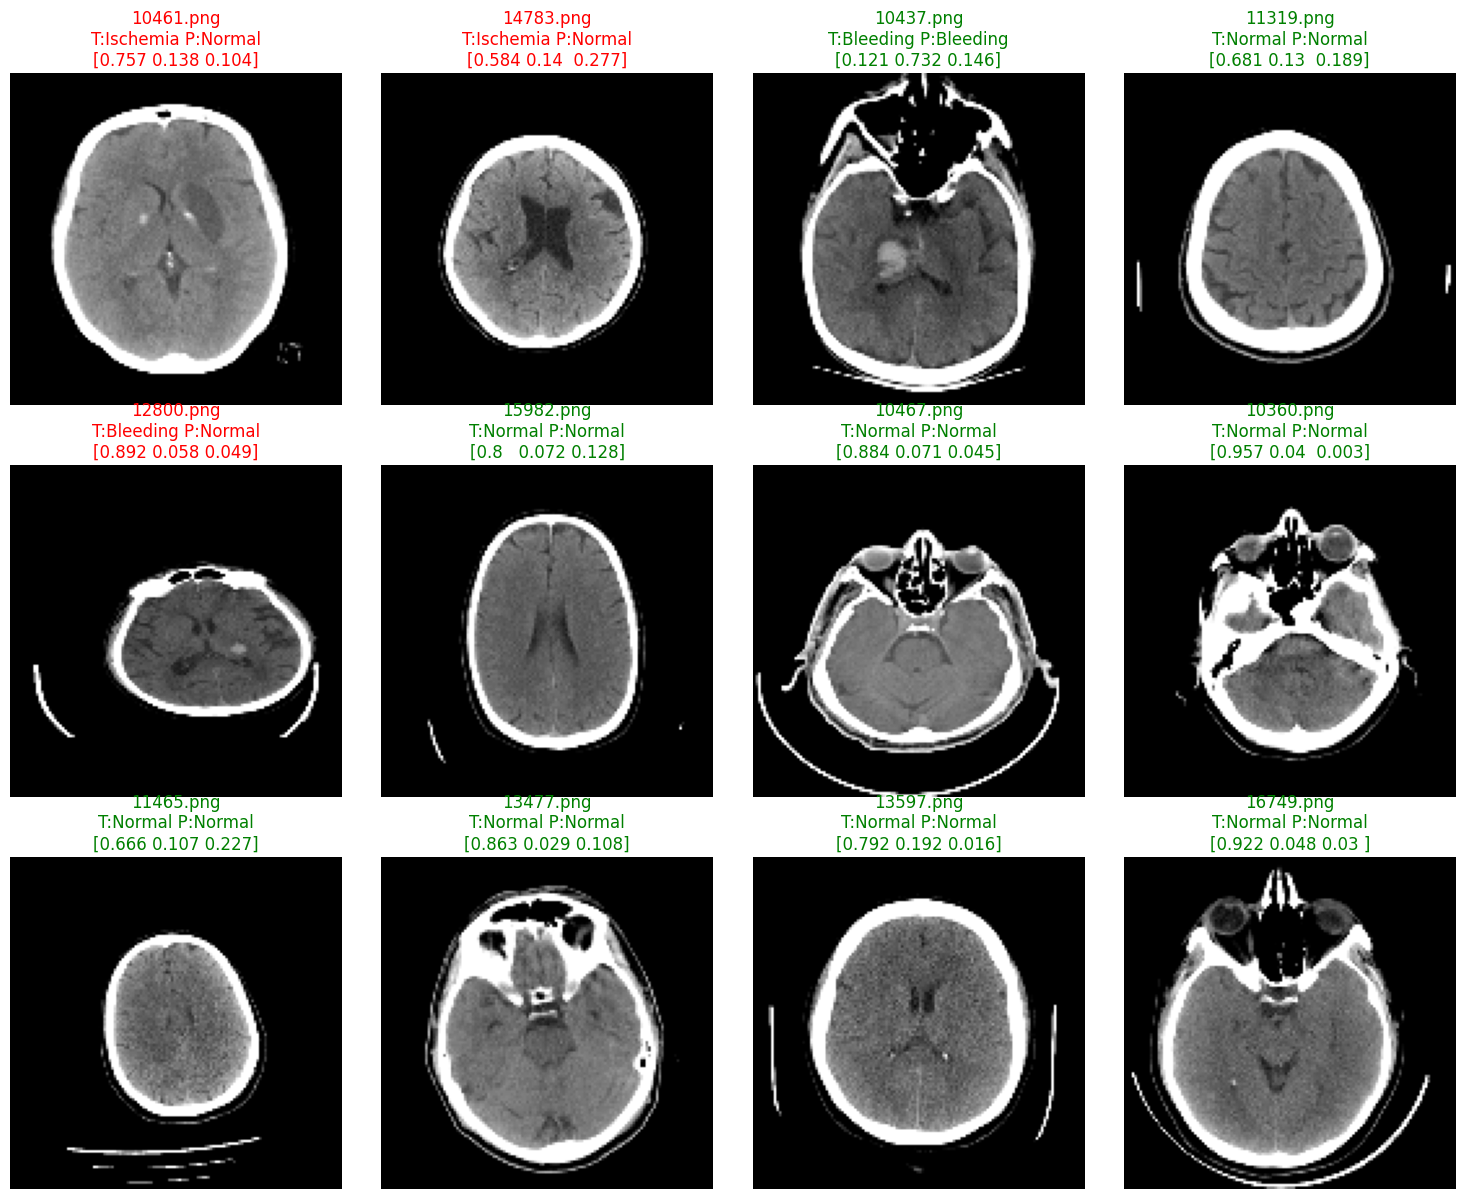

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

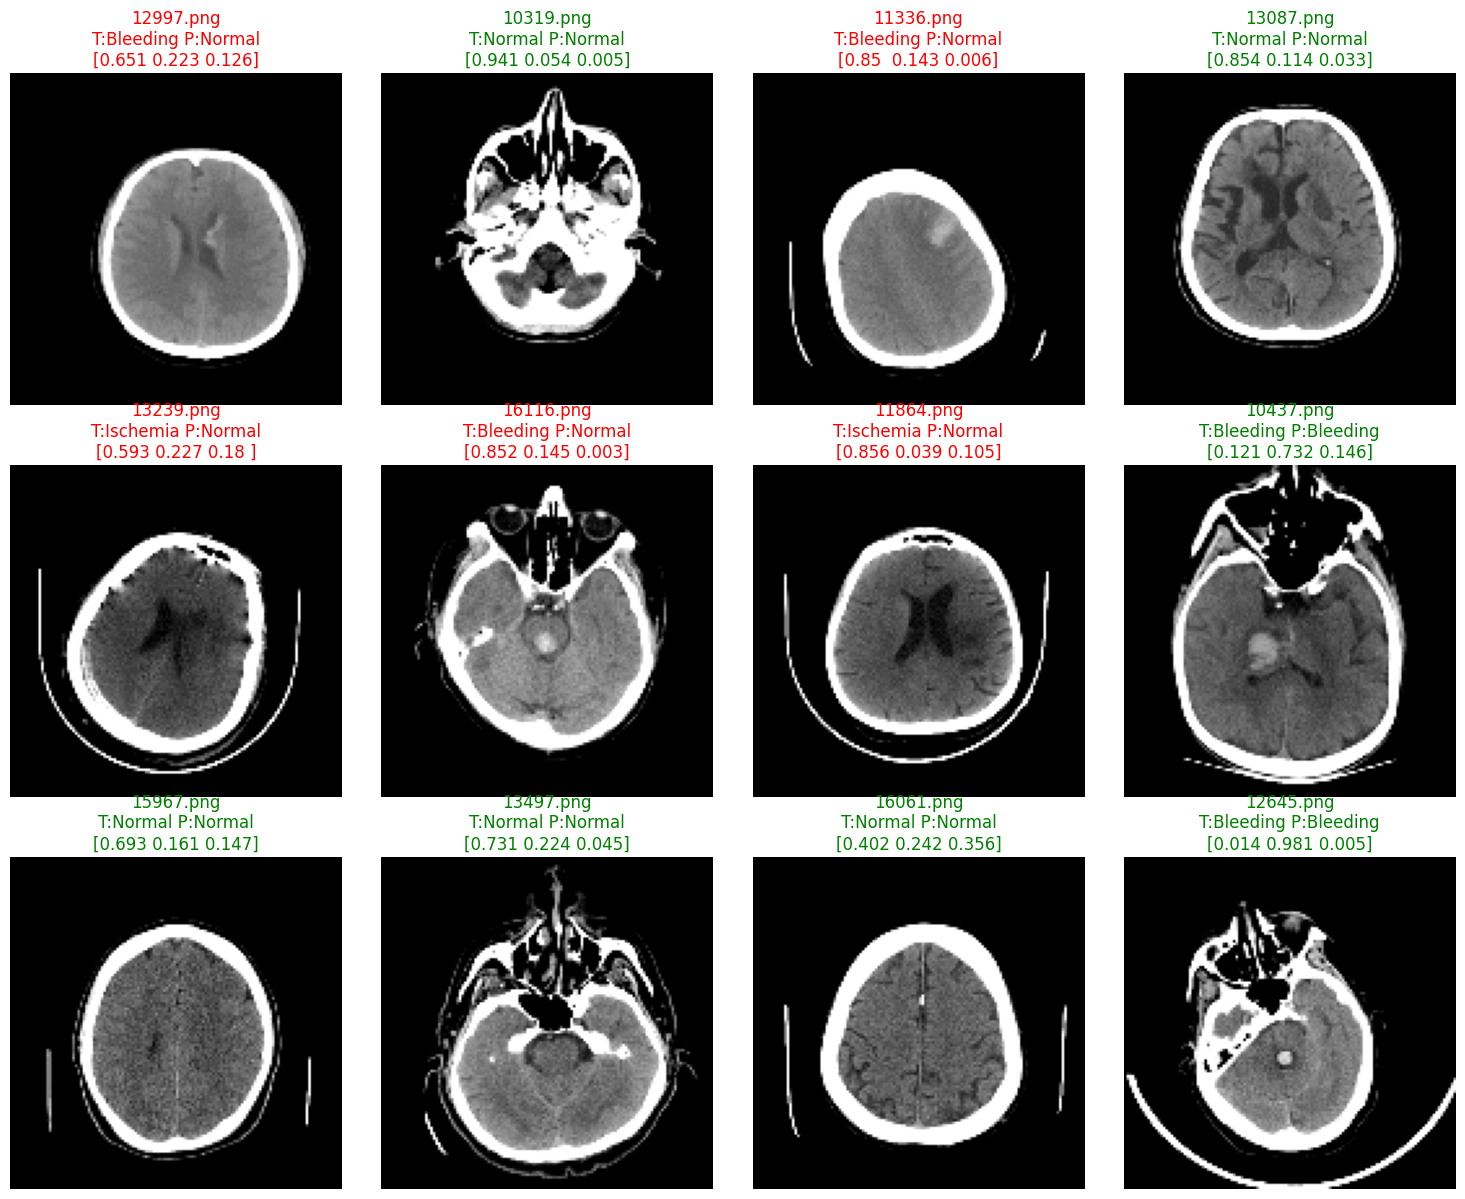

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

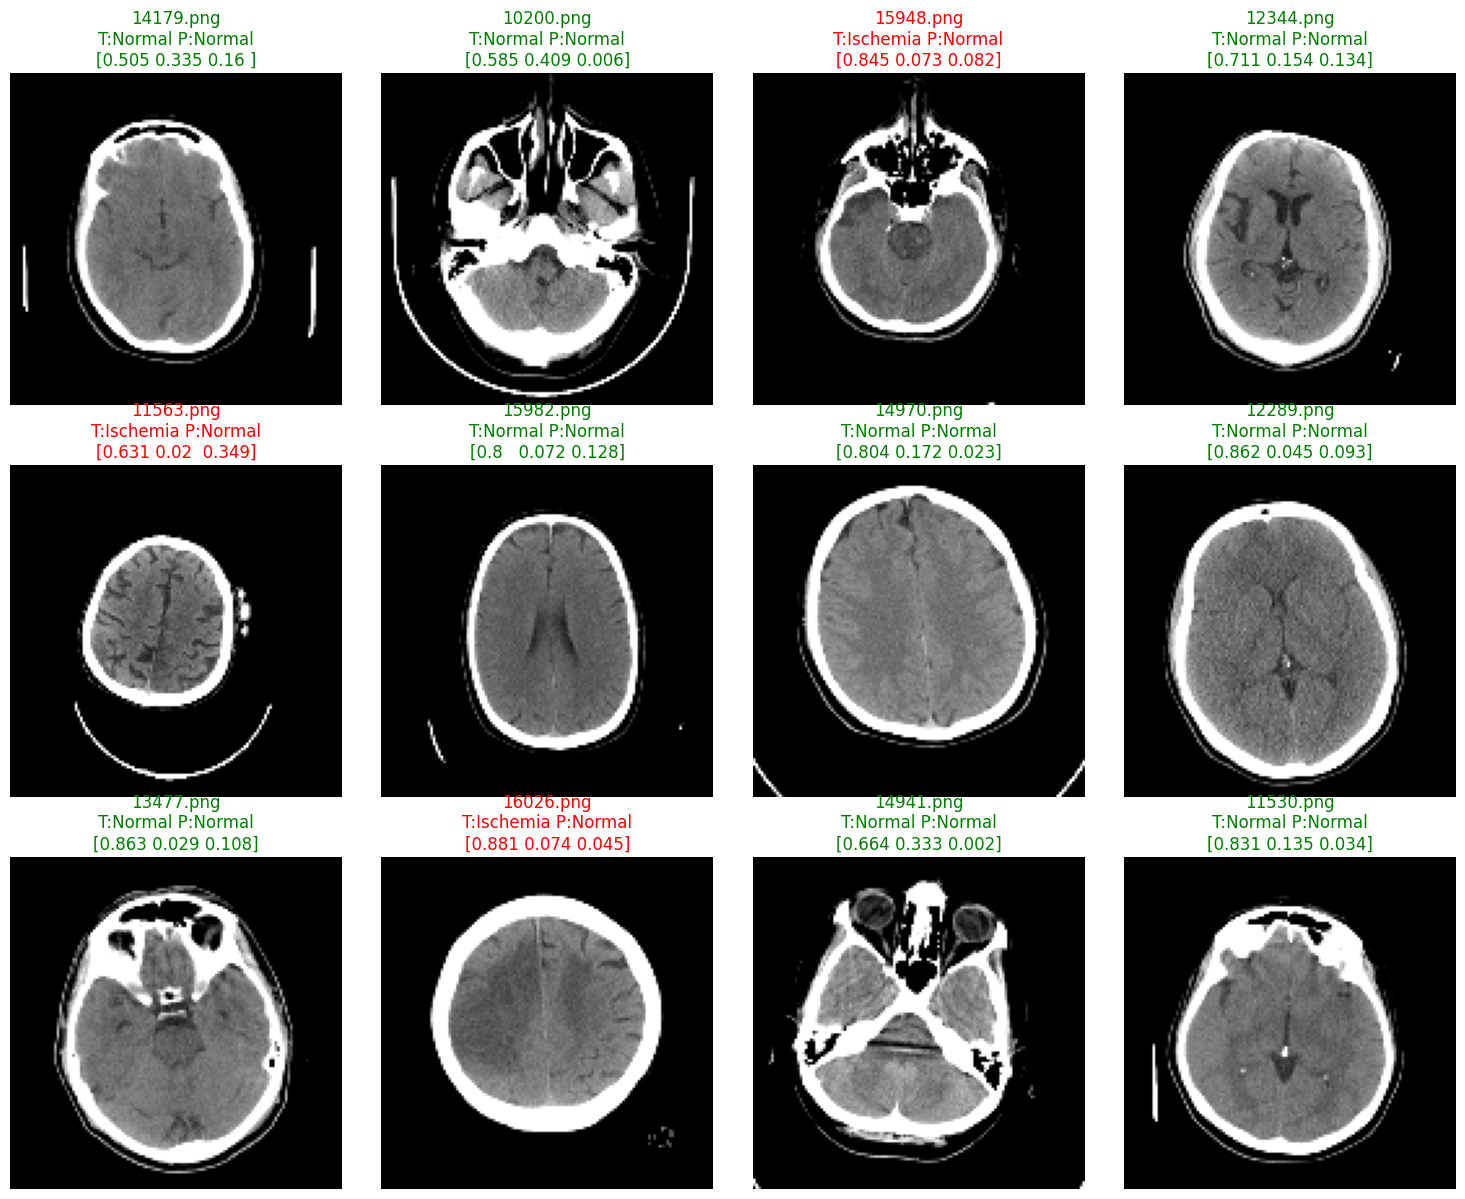

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

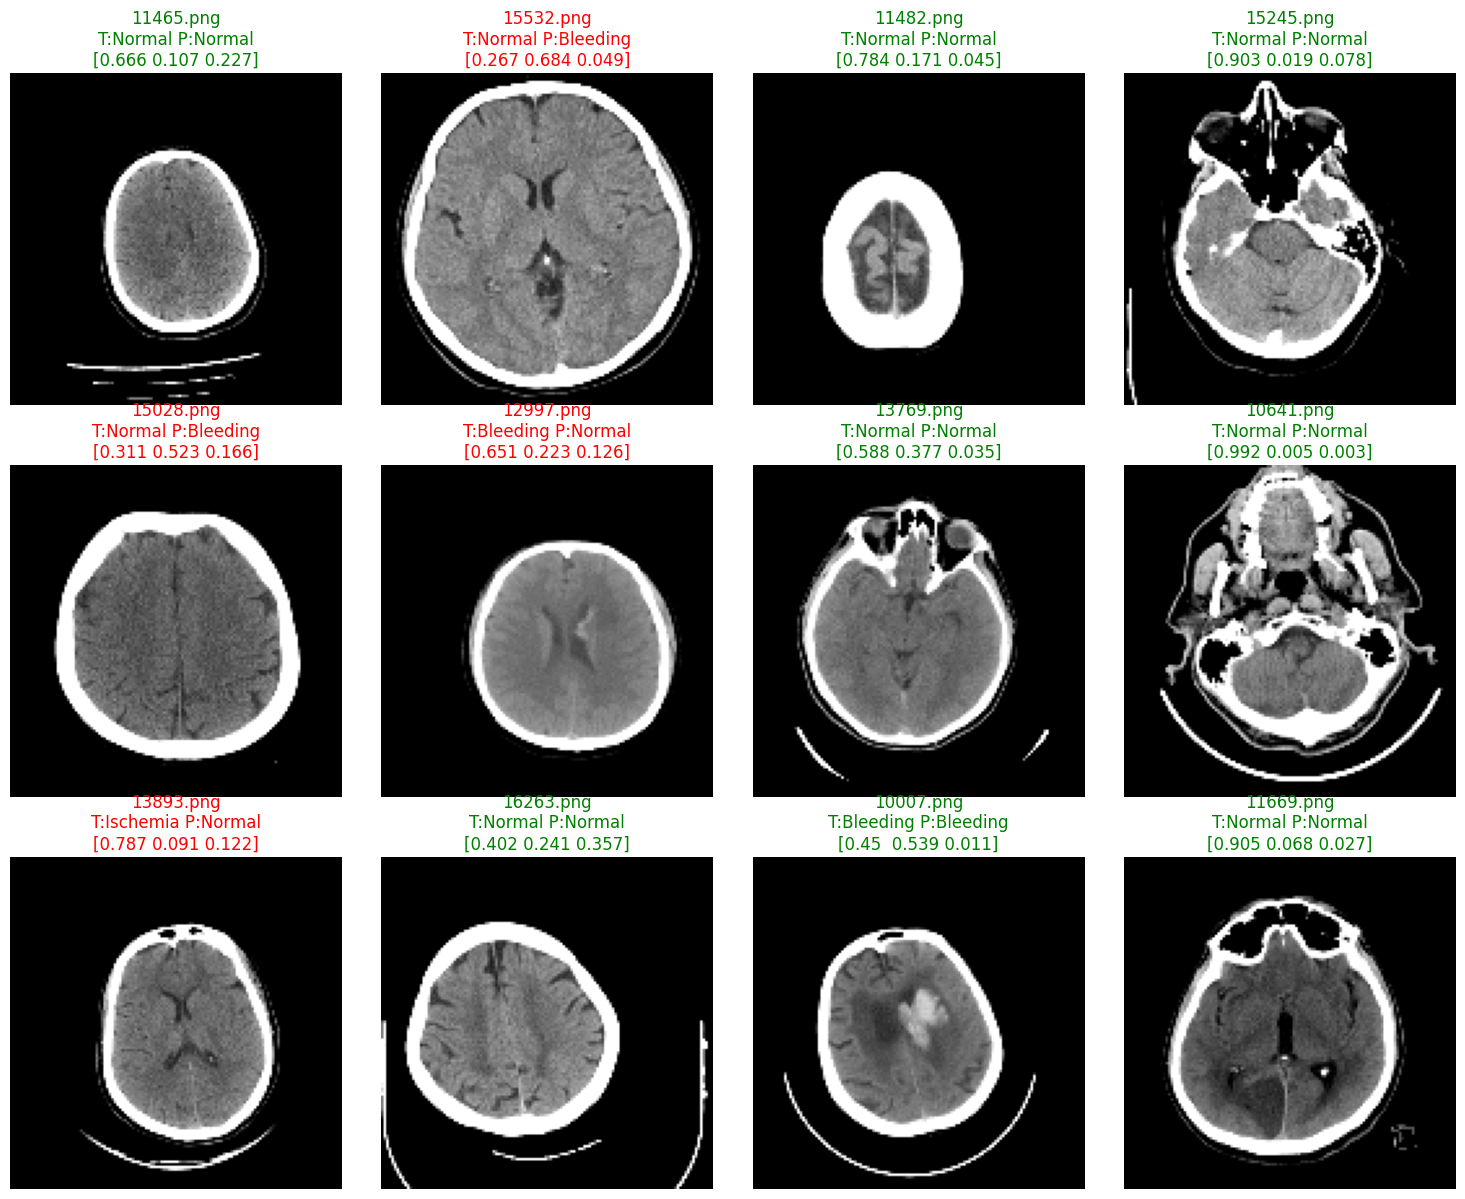

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)

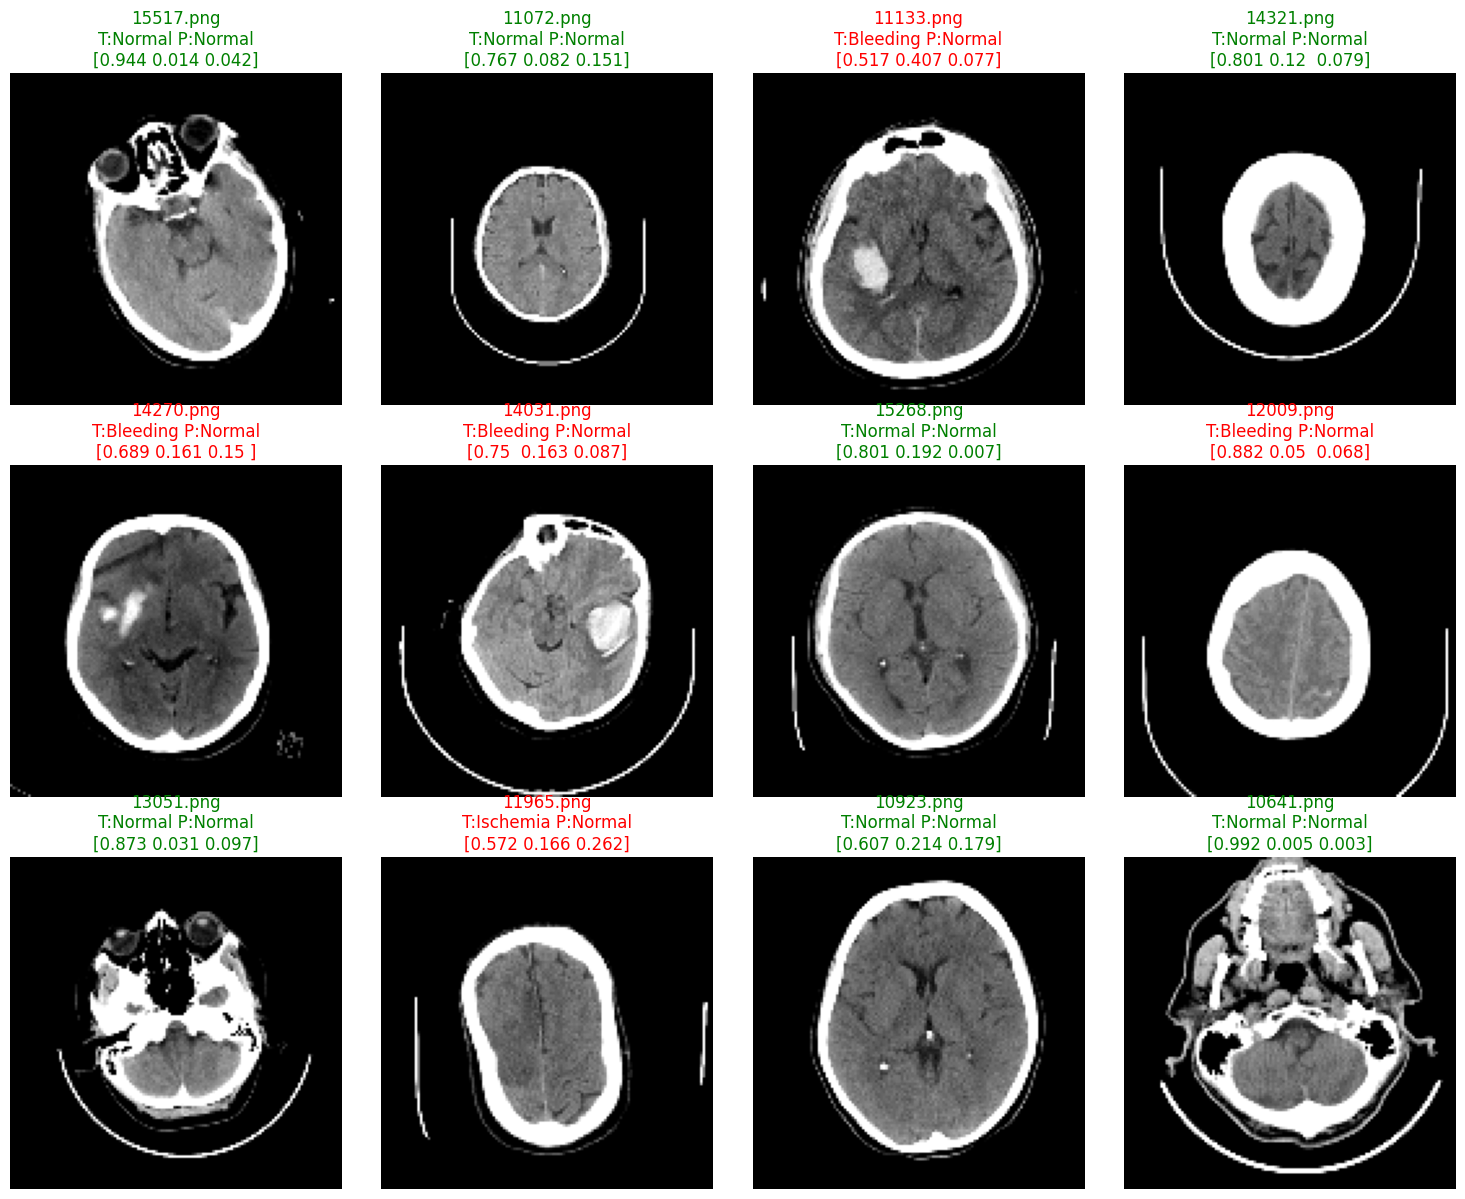

In [ ]:
show_test_predictions(model, test_paths, test_labels, n=12)